In [1]:
from helper_functions.get_data_dictionary_target_X_y_imports import *

Loaded: 
      data: the entire dataset.
      dictionary: the data dictionary.
      X: the features columns with 'inhospital_mortality', 'studyid_adm', 'lengthadm' dropped.
      y: the target column.


In [26]:
clincial_features = dictionary[dictionary.Category.str.contains('Clinical') & ~dictionary.Feature.str.contains('admitabx')].Feature.tolist()
for col in clincial_features:
    print("\n", col)
    print(data[col].dtype)
    if data[col].nunique()<10:
        print(data[col].unique())


 vaccpneumoc_adm
object
['3 doses' '2 doses' '0 doses' 'Unknown' '1 dose']

 spo2onoxy_adm
object
['No' 'Yes' nan]

 oxygenavail_adm
object
['Oxygen available and not being used' 'Oxygen available but not enough'
 'Oxygen available and being used' 'Oxygen not available']

 respdistress_adm
object
['No' 'Yes' nan]

 caprefill_adm
object
['No' 'Yes' nan]

 bcseye_adm
object
['Watches or follows' 'Fails to watch or follow' nan]

 bcsmotor_adm
object
['Localizes painful stimulus' 'Withdraws limb from painful stimulus'
 'No response or inappropriate response']

 bcsverbal_adm
object
['Cries appropriately with pain, or, if verbal, speaks'
 'Moan or abnormal cry with pain' 'No vocal response to pain' nan]

 bcgscar_adm
object
['Yes' 'No']

 vaccmeasles_adm
object
['Yes' 'No' 'Unknown' nan]

 vaccmeaslessource_adm
object
['Self report' 'Card' nan]

 vaccpneumocsource_adm
object
['Self report' 'Card' nan]

 vaccdpt_adm
object
['3 doses' '2 doses' '0 doses' 'Unknown' '1 dose' nan]

 vaccdptsour

In [2]:
## notes to investigate
#  
# flag - if there is no secondary latato reading, 
# low oxygen + low BCS + anemia flag 

# traveldistance 

In [3]:
import pandas as pd
import numpy as np
from functools import lru_cache

class FeatureEngineer:
    def __init__(self):
        """
        Initializes the Feature Engineer with predefined constants, including the feature keys
        and the file paths of the CDC and WHO Growth Charts for BMI and WFL z-score calculations.
        """
        # Primary feature keys
        self.primary_features_keys = [
            'agecalc_adm', 'height_cm_adm', 'weight_kg_adm', 'sex_adm',
            'caprefill_adm', 'glucose_mmolpl_adm', 'hematocrit_gpdl_adm',
            'lactate_mmolpl_adm', 'lactate2_mmolpl_adm', 'spo2site1_pc_oxi_adm',
            'spo2site2_pc_oxi_adm', 'sqi1_perc_oxi_adm', 'sqi2_perc_oxi_adm',
            'sysbp_mmhg_adm', 'diasbp_mmhg_adm', 'hr_bpm_adm', 'temp_c_adm',
            'bcseye_adm', 'bcsmotor_adm', 'bcsverbal_adm']

        # Target column for the dataset
        self.target_column = 'inhospital_mortality'

        # loading the BMI chart for z-score calculation
        self.bmi_csv_path = "charts/bmiagerev.csv"
        self.df_bmi = pd.read_csv(self.bmi_csv_path, skiprows=[220])

        # Loading the WFL percentiles data for z-score calculation
        self.wfl_csv_path = "charts/WHO-{gender}-Weight-for-length-Percentiles.csv"
        self.wfl_df = pd.concat(
            [pd.read_csv(f"{self.wfl_csv_path.format(gender=gender)}").assign(gender=gender) for gender in ['Boys', 'Girls']],
            ignore_index=True)
        
        # loading charts for Systolic and diastolic percentiles
        self.bp_filepath = "charts/BP_Percentiles.xlsx"
        self.bp_boys_chart = pd.read_excel(self.bp_filepath, 
                                sheet_name="Boys", 
                                index_col=[0,1],
                                header=[0, 1])
        self.bp_girls_chart = pd.read_excel(self.bp_filepath, 
                                sheet_name="Girls", 
                                index_col=[0,1],
                                header=[0, 1]) 

    def fit(self, X, y=None):
        """
        Placeholder method for fit.
        
        :param X: The input data (DataFrame)
        :param y: The target values
        """
        pass  # Not used in this case, but can be extended if needed
    
    def transform(self, X, y=None):
        """
        Transforms the dataset by handling missing values, engineering secondary features,
        and preparing the final dataset.

        :param X: The input data (DataFrame)
        :param y: The target values
        :return: Transformed DataFrame with primary and secondary features
        """
        X = X.copy()
        # Step 1: Select only the primary features columns
        X = X[self.primary_features_keys]
        
        # Step 2: Fill missing values in specific columns
        X["lactate2_mmolpl_adm"].fillna(X["lactate_mmolpl_adm"], inplace=True)
        X["spo2site2_pc_oxi_adm"].fillna(X["spo2site1_pc_oxi_adm"], inplace=True)
        X["sqi2_perc_oxi_adm"].fillna(X["sqi1_perc_oxi_adm"], inplace=True)
        
        # Step 3: Drop rows with missing values
        X[target] = y
        X = X.dropna()
        y = X[target]
        
        # Step 4: Engineer the secondary features
        ## A higher shock index indicates worse perfusion and is associated with shock.
        X['shock_index'] = X['hr_bpm_adm'] / X['sysbp_mmhg_adm']
        # MAP < 65 mmHg is a sign of hypotension and poor perfusion.
        X['map'] = X['diasbp_mmhg_adm'] + X['sysbp_mmhg_adm'] / 3 - X['diasbp_mmhg_adm']
        X['hypotension_flag'] = np.where(X['map'] < 65, False, True)
        # lactate clearance < 10%: Associated with poor outcomes, including higher mortality and organ failure. 
        # a negative value indicates rising lactate (worsening tissue hypoxia)
        X['lactate_clearance'] = 100 * (X['lactate_mmolpl_adm'] - X['lactate2_mmolpl_adm']) / X['lactate_mmolpl_adm']
        X['hypoxia_flag'] = np.where(X['lactate_clearance'] < 10, False, True)
        X['extreme_hypoxia_flag'] = np.where(X['lactate_clearance'] < 0, False, True)

        # Step 5: Calculate the Blantyre_coma_scale
        # The minimum score is 0 which indicates poor results while the maximum is 5 indicating good results. 
        # All scores under 5 are considered abnormal
        X['bcseye_numeric'] = np.where(X['bcseye_adm'] == "Watches or follows", 1, 0)
        X['bcsverbal_numeric'] = np.where(X['bcsverbal_adm'] == 'Cries appropriately with pain, or, if verbal, speaks', 1, 0)
        conditions = [
            X['bcsmotor_adm'] == 'Localizes painful stimulus',
            X['bcsmotor_adm'] == 'Withdraws limb from painful stimulus',
            X['bcsmotor_adm'] == 'No response or inappropriate response']
        values = [2, 1, 0]
        X['bcsmotor_numeric'] = np.select(conditions, values, default=0)
        X['bcs_adm'] = X['bcseye_numeric'] + X['bcsverbal_numeric'] + X['bcsmotor_numeric']
        X['bcs_adm'] = (X['bcs_adm']).astype('category')

        X['bcs_flag'] = np.where(X['bcs_adm'] == 5, False, True)
                
        # Step 6: Calculate and add Z-scores to X
        X['z_score'] = self._calculate_z_score(
            X['sex_adm'], X['agecalc_adm'], X['height_cm_adm'], X['weight_kg_adm']
        )

        # Step 7: Calculate the sys and dias percentiles
        # Prepare X DataFrame with age lookup
        X['age_lookup'] = np.where(X['agecalc_adm'] > 6, 
                                   np.round(X['agecalc_adm']/12), 1.0)  # Round the age to years

        # Convert sex_adm to boolean for efficiency
        X['is_male'] = X['sex_adm'].str.lower() == 'male'

        # Apply the function with optimized series creation
        results = X.apply(lambda row: self._calculate_bp_percentiles(
            age_lookup=row['age_lookup'],
            is_male=row['is_male'], 
            height_cm_adm=row['height_cm_adm'],
            sysbp_mmhg_adm=row['sysbp_mmhg_adm'],
            diasbp_mmhg_adm=row['diasbp_mmhg_adm']
        ), axis=1).tolist()

        X[['systolic_percentile', 'diastolic_percentile']] = pd.DataFrame(results, index=X.index)
        X['sys_rank'] = self._map_percentile_to_rank(X['systolic_percentile'], bp_type="systolic")
        X['dias_rank'] = self._map_percentile_to_rank(X['diastolic_percentile'], bp_type="diastolic")
        X.drop(columns=['age_lookup', 'is_male',
                        'systolic_percentile', 'diastolic_percentile'], inplace=True)

        # Step 7: Enhance primary features

        # 1 if glucose < 4 mmol/L (hypoglycemia) or > 10 mmol/L (hyperglycemia), 0 otherwise
        X['glycemia_flag'] = np.where((X['glucose_mmolpl_adm'] >= 4) & (X['glucose_mmolpl_adm'] <= 10), False, True)

        # 1 if hematocrit < 30% (anemia), 0 otherwise
        X['anemia_flag'] = np.where(X['hematocrit_gpdl_adm'] >= 30, False, True)
        # 1 if hematocrit < 20% (anemia), 0 otherwise
        X['severe_anemia_flag'] = np.where(X['hematocrit_gpdl_adm'] >= 20, False, True)

        # 1 if lactate ≥ 2.0 mmol/L (hyperlactatemia), 0 otherwise
        X['hyperlactatemia_flag'] = np.where(X['lactate_mmolpl_adm'] < 2, False, True)

        # 1 if lactate ≥ 4.0 mmol/L (lactic acidosis), 0 otherwise
        X['lactic_acidosis_flag'] = np.where(X['lactate_mmolpl_adm'] < 5, False, True)

        # 1 if temperature > 38°C (fever) or < 36°C (hypothermia), 0 otherwise
        X['hypo_hyper_thermia_flag'] = np.where(
            (X['temp_c_adm'] > 36) & (X['temp_c_adm'] < 38), False, True)

        # Select the more reliable SpO2 value based on SQI
        conditions = [
            X['sqi1_perc_oxi_adm'] > X['sqi2_perc_oxi_adm'],
            X['sqi2_perc_oxi_adm'] > X['sqi1_perc_oxi_adm'],
            np.isclose(X['sqi1_perc_oxi_adm'], X['sqi2_perc_oxi_adm'], atol=0.01)  # Adjust tolerance if needed
        ]
        choices = [
            X['spo2site1_pc_oxi_adm'],
            X['spo2site2_pc_oxi_adm'],
            np.minimum(X['spo2site1_pc_oxi_adm'], X['spo2site2_pc_oxi_adm'])
        ]
        X['spo_selected'] = np.select(conditions, choices, default=np.nan)  # Default can be adjusted if needed
        
        # 1 if SpO2: < 95% on room air (hypoxemia), 0 otherwise
        X['hypoxemia_flag'] = np.where(X['spo_selected'] >95, False, True)
        
        # Step Last: Return the transformed DataFrame
        return X


    def fit_transform(self, X, y=None):
        """
        Combines fit and transform methods.
        """
        self.fit(X, y)
        return self.transform(X, y)

    def _calculate_bmi_zscore(self, sex_adm, agecalc_adm, height_cm_adm, weight_kg_adm):
        """Vectorized BMI-for-age z-score calculation for children > 24 months."""
        bmi = weight_kg_adm / ((height_cm_adm / 100) ** 2)  # Vectorized BMI calculation

        # Convert "Male"/"Female" to 1/2 and filter in a vectorized manner
        sex_code = np.where(sex_adm.str.lower() == "male", 1, 2)
        df = self.df_bmi[self.df_bmi["Sex"].isin(sex_code)]
        df = df.sort_values("Agemos")

        # Perform merge_asof in a vectorized way
        age_df = pd.DataFrame({"Agemos": agecalc_adm})
        merged = pd.merge_asof(age_df.sort_values("Agemos"), df, on="Agemos", direction="nearest")

        L, M, S = merged[['L', 'M', 'S']].values.T  # Extract L, M, S as arrays
        z_scores = ((bmi / M) ** L - 1) / (L * S)  # Vectorized z-score calculation

        return z_scores

    def _calculate_wfl_zscore(self, sex_adm, height_cm_adm, weight_kg_adm):
        """Vectorized weight-for-length z-score calculation for children ≤ 24 months."""
        # Filter the DataFrame based on sex_adm
        sex_code = np.where(sex_adm.str.lower() == "male", 'Boys', 'Girls')
        df = self.wfl_df[self.wfl_df["gender"].isin(sex_code)].sort_values("Length")

        # Perform merge_asof in a vectorized way
        length_df = pd.DataFrame({"Length": height_cm_adm})
        merged = pd.merge_asof(length_df.sort_values("Length"), df, on="Length", direction="nearest")

        L, M, S = merged[['L', 'M', 'S']].values.T  # Extract L, M, S as arrays
        z_scores = ((weight_kg_adm / M) ** L - 1) / (L * S)  # Vectorized z-score calculation

        return z_scores

    def _calculate_z_score(self, sex_adm, agecalc_adm, height_cm_adm, weight_kg_adm):
        """Vectorized function to determine and calculate the correct z-score."""
        z_scores = np.where(
            agecalc_adm > 24,
            self._calculate_bmi_zscore(sex_adm, agecalc_adm, height_cm_adm, weight_kg_adm),
            self._calculate_wfl_zscore(sex_adm, height_cm_adm, weight_kg_adm)
        )
        return z_scores
    
    @lru_cache(maxsize=1024)
    def _lookup_bp_tables(self, height_cm_adm, hr_bpm_adm, age_lookup, is_male, is_diastolic):  # More arguments!
        bp_chart = self.bp_boys_chart if is_male else self.bp_girls_chart
        bp_data = bp_chart.loc[age_lookup, 'Diastolic BP (mm Hg)' if is_diastolic else 'Systolic BP (mm Hg)']

        height_row = bp_data.loc["Measured height (cm)", :]
        closest_height_index = height_row.sub(height_cm_adm).abs().idxmin()
        heart_rate_values = bp_data[closest_height_index].iloc[1:].astype(float) # Ensure float type for comparison

        min_hr = heart_rate_values.min()
        max_hr = heart_rate_values.max()

        if hr_bpm_adm <= min_hr:
            return (None, heart_rate_values.index[0])
        elif hr_bpm_adm >= max_hr:
            return (heart_rate_values.index[-1], None)
        else:
            lower_percentile = heart_rate_values[heart_rate_values <= hr_bpm_adm].index[-1]
            upper_percentile = heart_rate_values[heart_rate_values > hr_bpm_adm].index[0]
            return (lower_percentile, upper_percentile)

    def _calculate_bp_percentiles(self, age_lookup, is_male, height_cm_adm, sysbp_mmhg_adm, diasbp_mmhg_adm):  # is_male as argument
        diastolic_percentile = self._lookup_bp_tables(height_cm_adm, diasbp_mmhg_adm, age_lookup, is_male, True)
        systolic_percentile = self._lookup_bp_tables(height_cm_adm, sysbp_mmhg_adm, age_lookup, is_male, False)
        return systolic_percentile, diastolic_percentile

    def _map_percentile_to_rank(self, percentile_column, bp_type):
        conditions = [
            percentile_column == (None, '50th'),
            percentile_column == ('50th', '90th'),
            percentile_column == ('90th', '95th'),
            percentile_column == ('95th', '95th + 12 mm Hg'),
            percentile_column == ('95th + 12 mm Hg', None)
        ]
        
        choices = [
            "Hypotension",
            f"Normal {bp_type.capitalize()} BP",  
            f"Elevated {bp_type.capitalize()} BP",
            "Hypertension",
            "Stage 2 Hypertension"]
        
        return np.select(conditions, choices, default="Undefined")


In [4]:
tmp = data.drop(columns=['studyid_adm', 'lengthadm'],
               errors='ignore').copy()

X_ = tmp.drop(columns=target)
y_ = tmp[target]
feature = FeatureEngineer()

X = X_[[
            'agecalc_adm', 'height_cm_adm', 'weight_kg_adm', 'sex_adm',
            'caprefill_adm', 'glucose_mmolpl_adm', 'hematocrit_gpdl_adm',
            'lactate_mmolpl_adm', 'lactate2_mmolpl_adm', 'spo2site1_pc_oxi_adm',
            'spo2site2_pc_oxi_adm', 'sqi1_perc_oxi_adm', 'sqi2_perc_oxi_adm',
            'sysbp_mmhg_adm', 'diasbp_mmhg_adm', 'hr_bpm_adm', 'temp_c_adm',
            'bcseye_adm', 'bcsmotor_adm', 'bcsverbal_adm']]
print(X.shape)

X = feature.fit_transform(X, y)
print(X.columns)

(2148, 20)
Index(['agecalc_adm', 'height_cm_adm', 'weight_kg_adm', 'sex_adm',
       'caprefill_adm', 'glucose_mmolpl_adm', 'hematocrit_gpdl_adm',
       'lactate_mmolpl_adm', 'lactate2_mmolpl_adm', 'spo2site1_pc_oxi_adm',
       'spo2site2_pc_oxi_adm', 'sqi1_perc_oxi_adm', 'sqi2_perc_oxi_adm',
       'sysbp_mmhg_adm', 'diasbp_mmhg_adm', 'hr_bpm_adm', 'temp_c_adm',
       'bcseye_adm', 'bcsmotor_adm', 'bcsverbal_adm', 'inhospital_mortality',
       'shock_index', 'map', 'hypotension_flag', 'lactate_clearance',
       'hypoxia_flag', 'extreme_hypoxia_flag', 'bcseye_numeric',
       'bcsverbal_numeric', 'bcsmotor_numeric', 'bcs_adm', 'bcs_flag',
       'z_score', 'sys_rank', 'dias_rank', 'glycemia_flag', 'anemia_flag',
       'severe_anemia_flag', 'hyperlactatemia_flag', 'lactic_acidosis_flag',
       'hypo_hyper_thermia_flag', 'spo_selected', 'hypoxemia_flag'],
      dtype='object')


# Visualizations

Index(['agecalc_adm', 'glucose_mmolpl_adm', 'hematocrit_gpdl_adm',
       'lactate_mmolpl_adm', 'lactate2_mmolpl_adm', 'sysbp_mmhg_adm',
       'diasbp_mmhg_adm', 'hr_bpm_adm', 'temp_c_adm', 'shock_index', 'map',
       'lactate_clearance', 'z_score', 'spo_selected'],
      dtype='object')
{'glycemia_flag', 'severe_anemia_flag', 'lactic_acidosis_flag', 'hypoxemia_flag', 'hyperlactatemia_flag', 'hypo_hyper_thermia_flag', 'anemia_flag', 'hypoxia_flag', 'sys_rank', 'sex_adm', 'caprefill_adm', 'hypotension_flag', 'dias_rank', 'bcs_adm', 'extreme_hypoxia_flag', 'bcs_flag'}


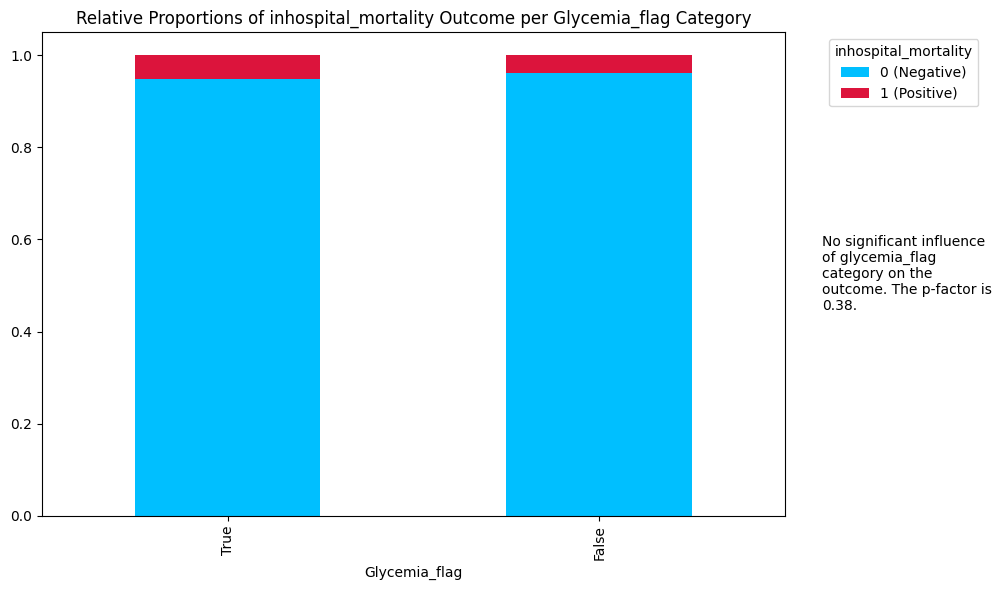

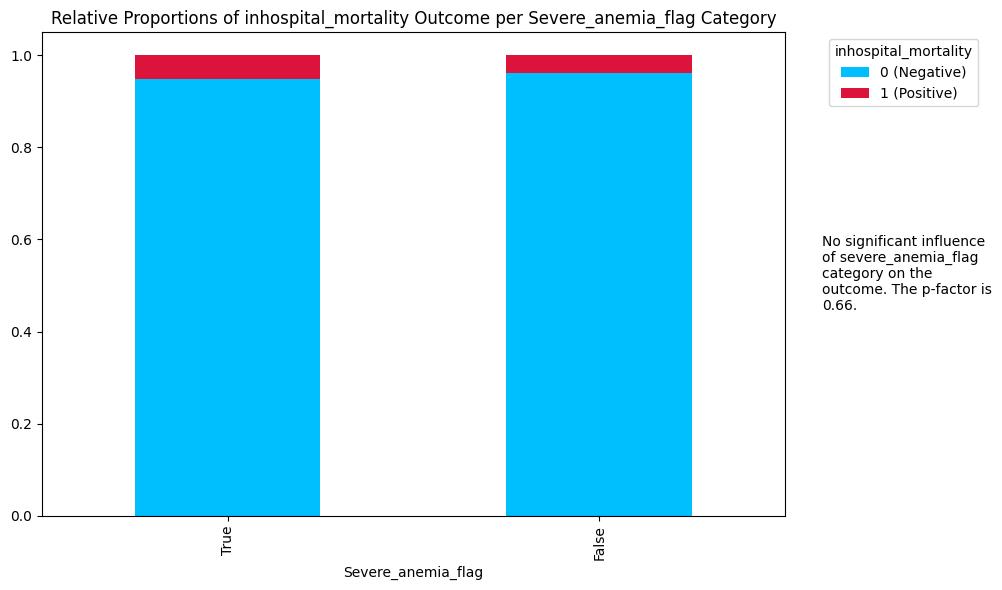

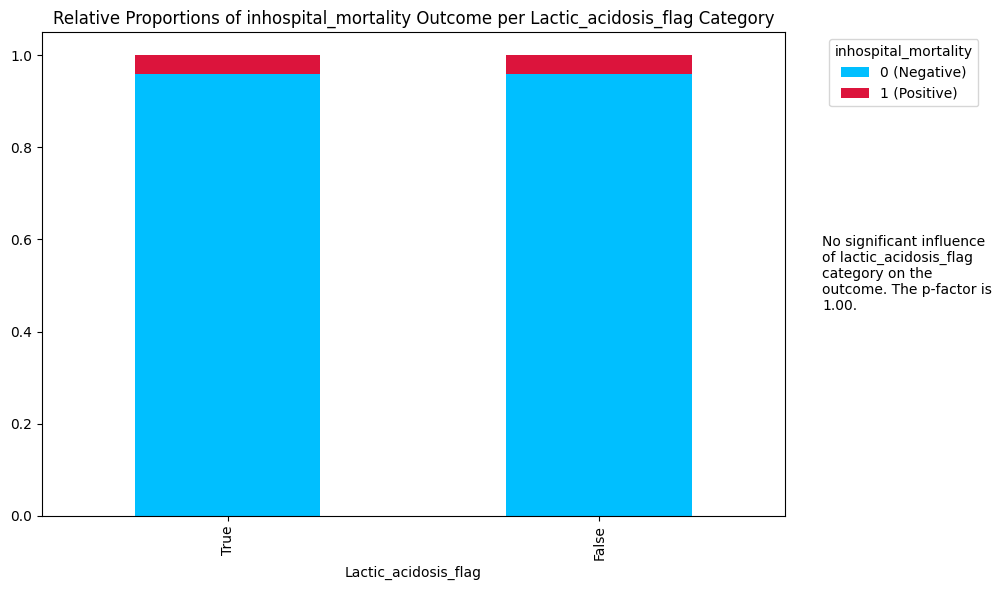

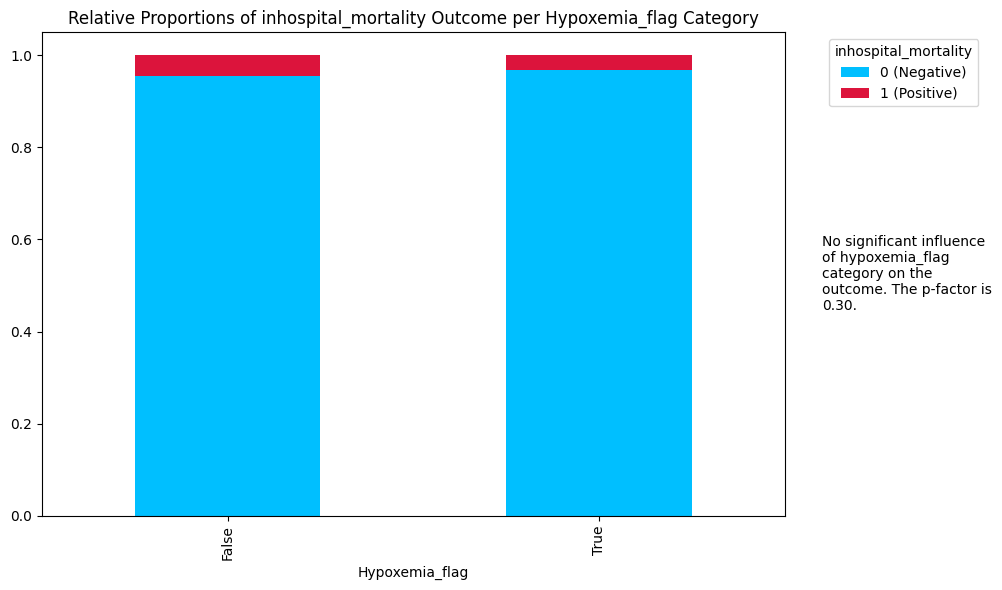

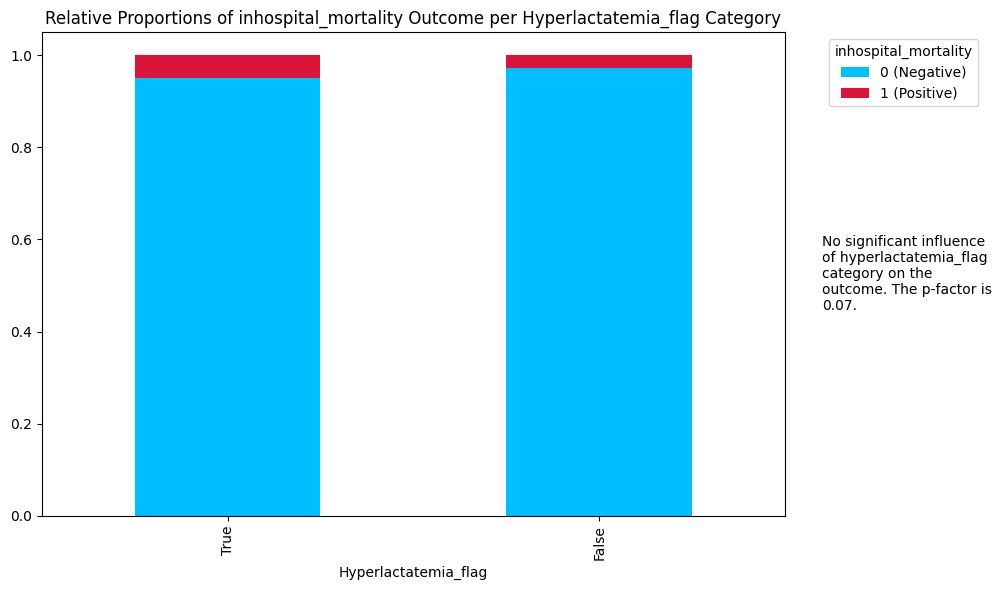

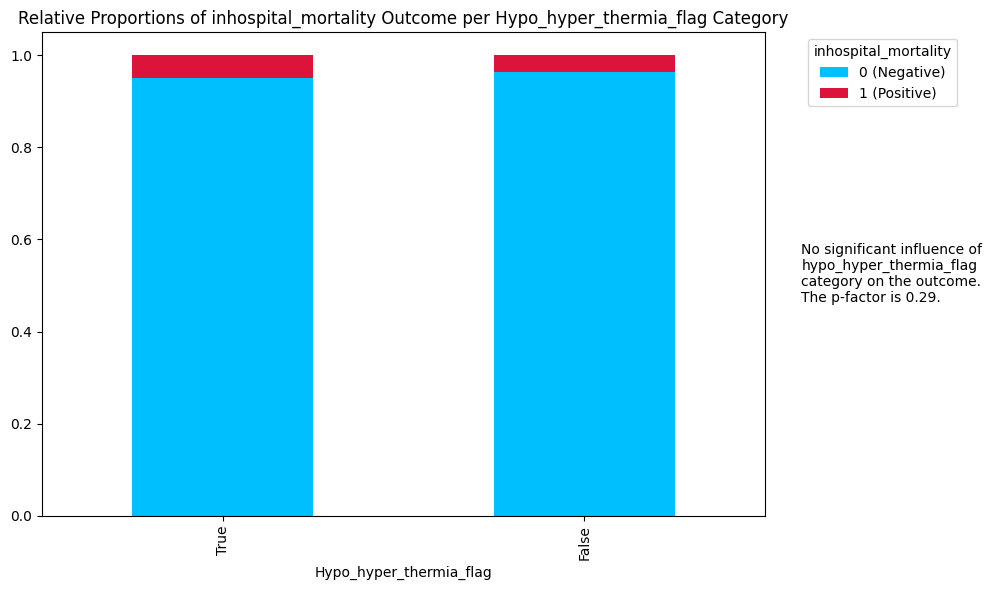

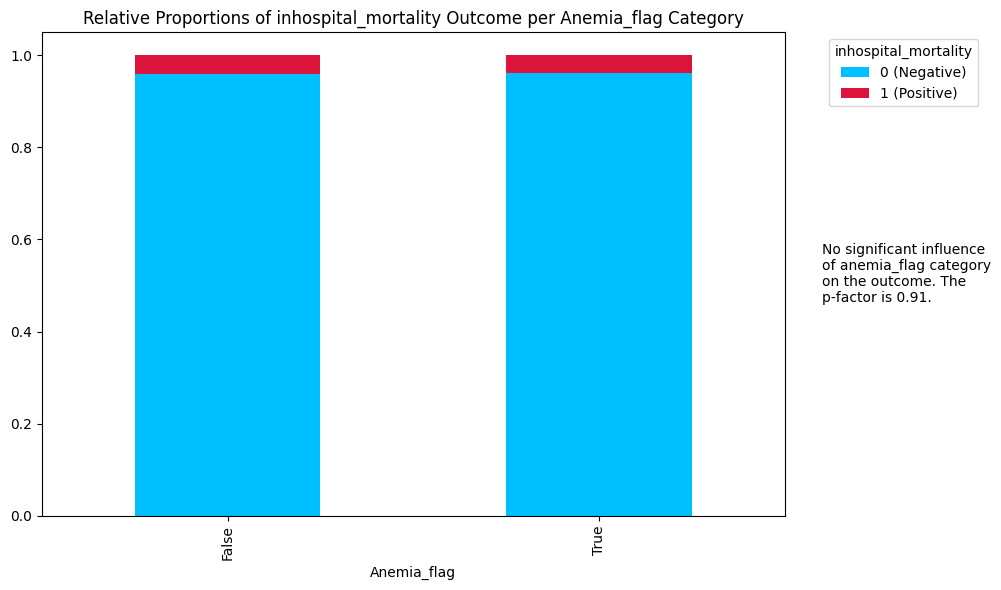

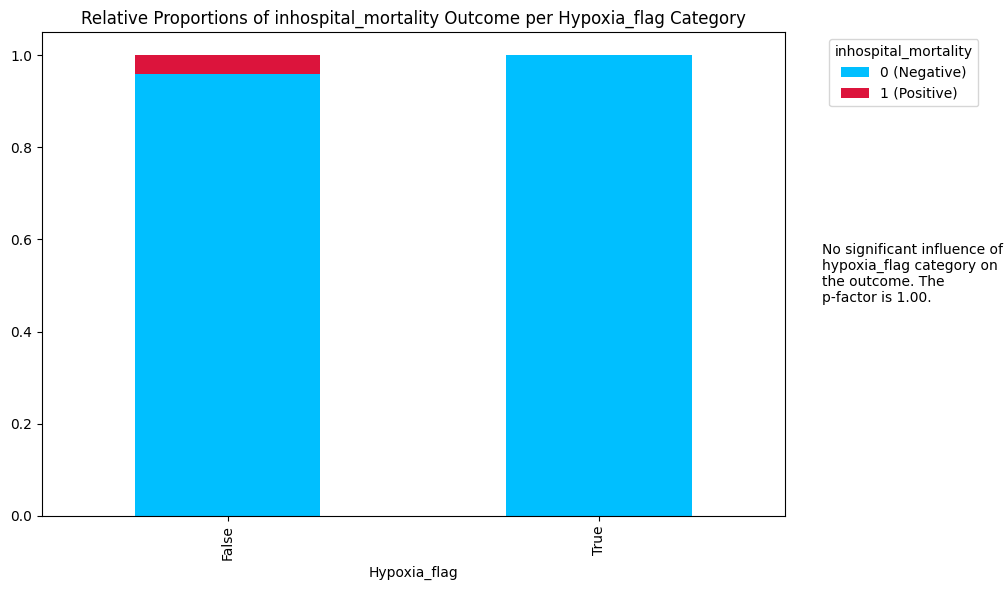

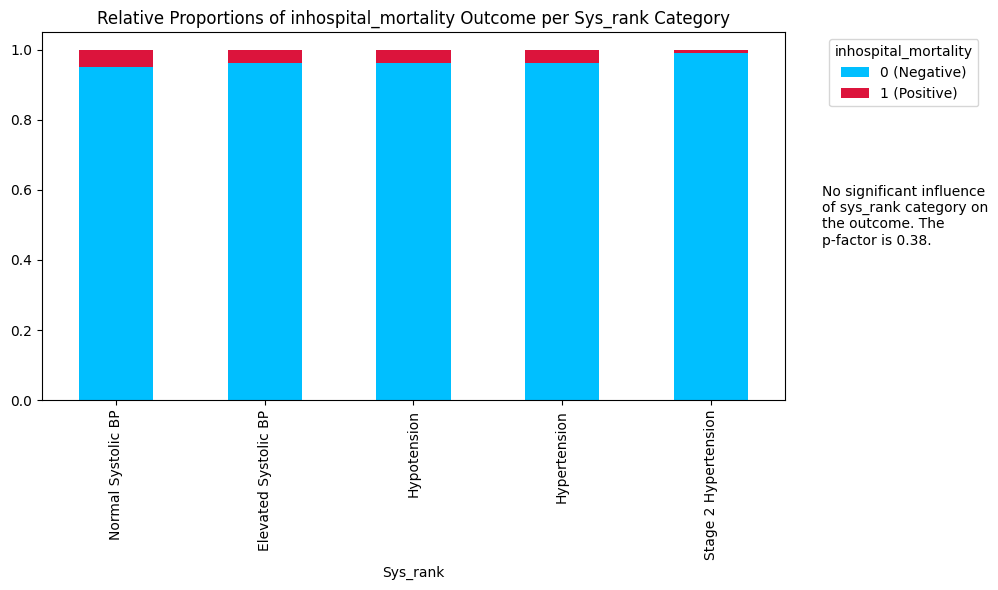

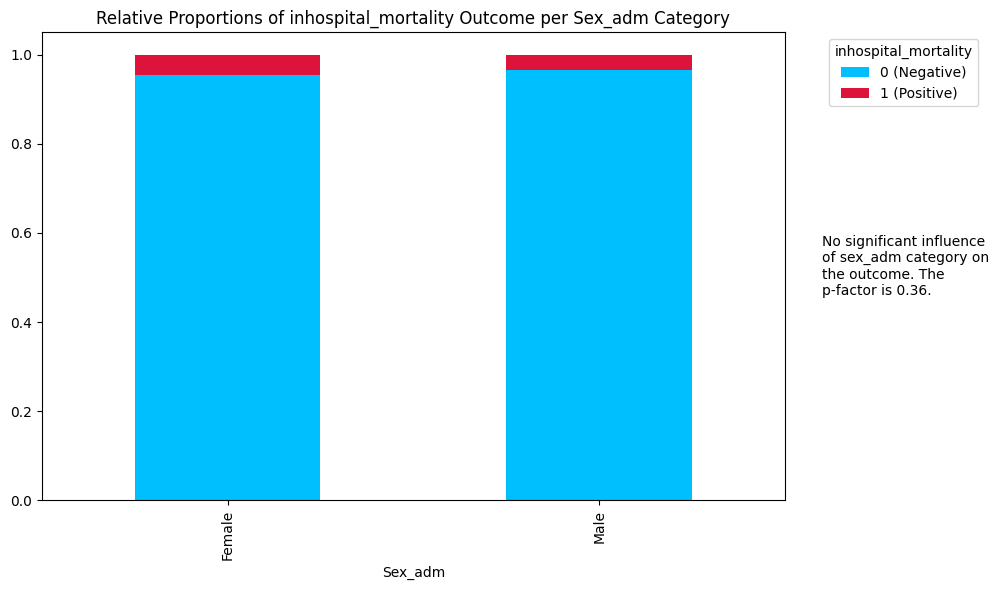

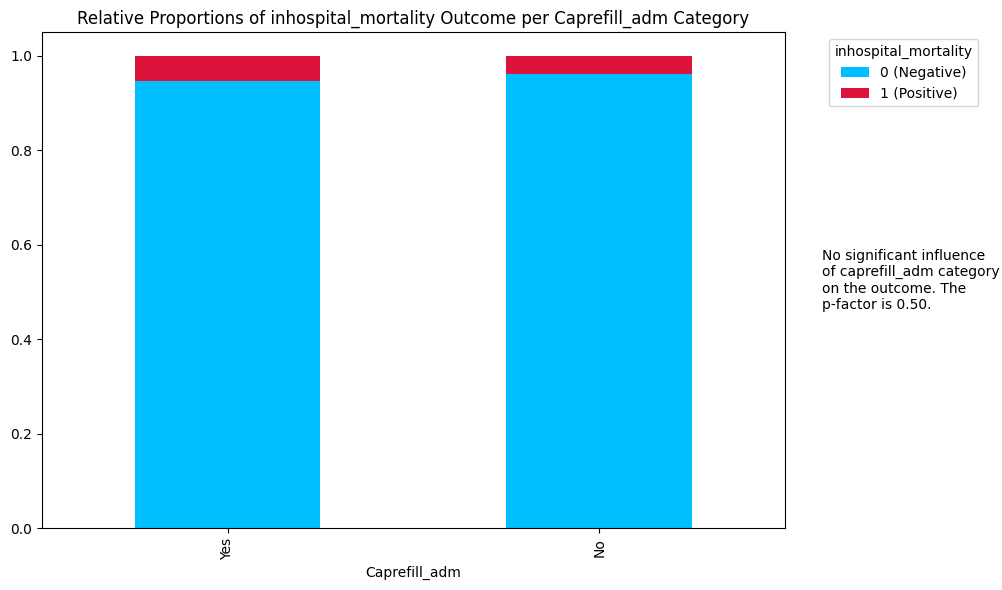

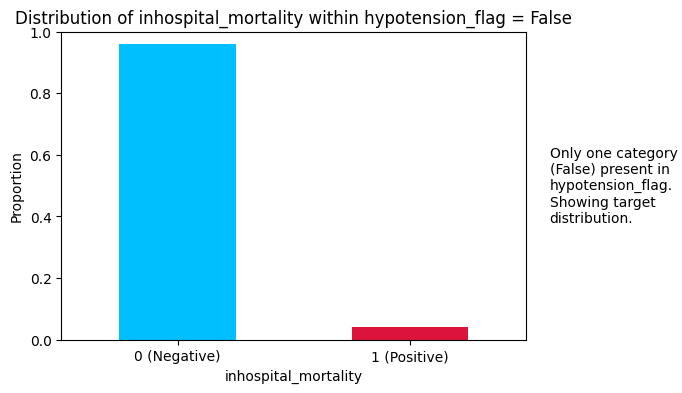

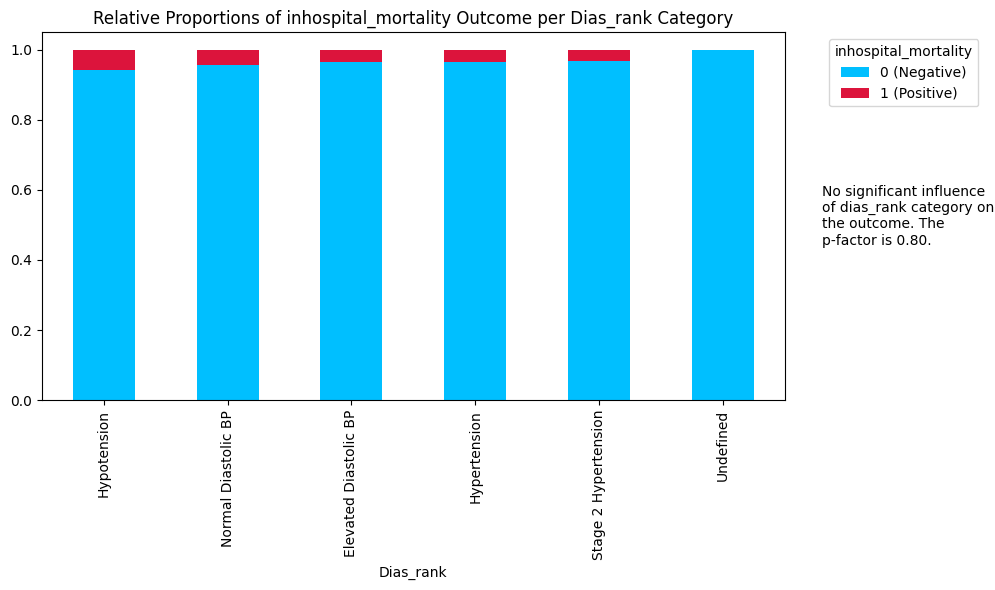

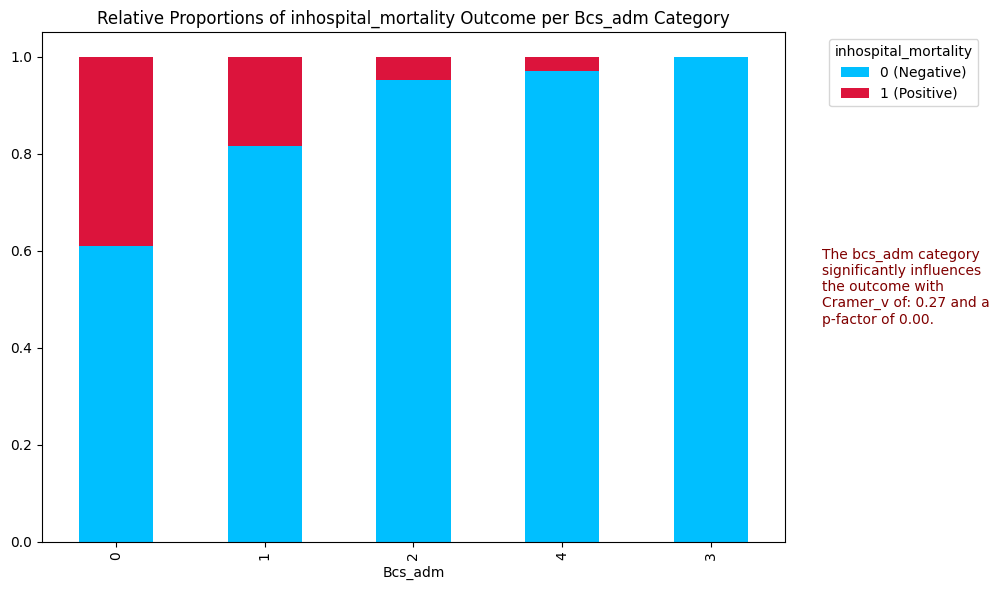

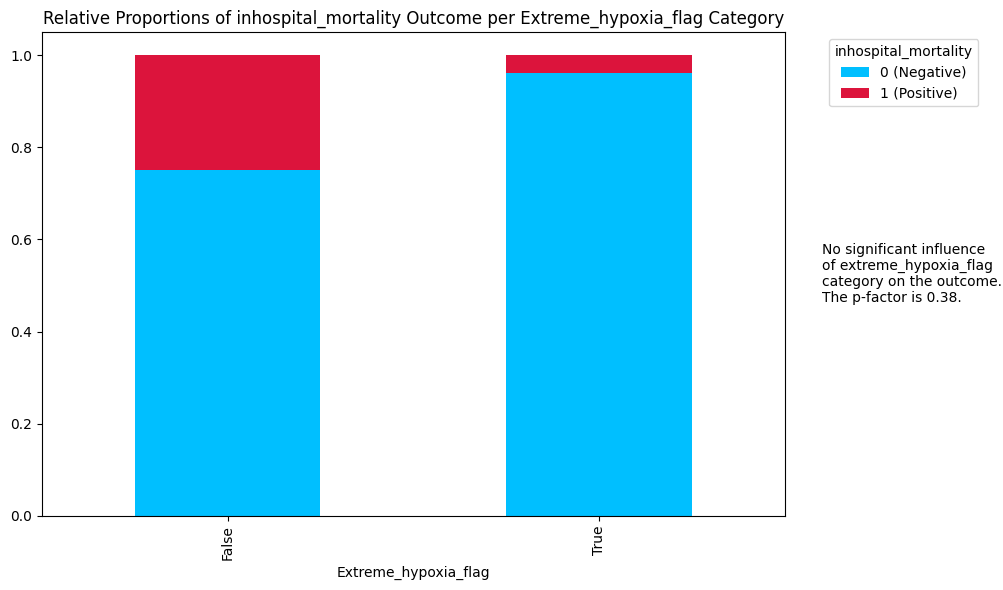

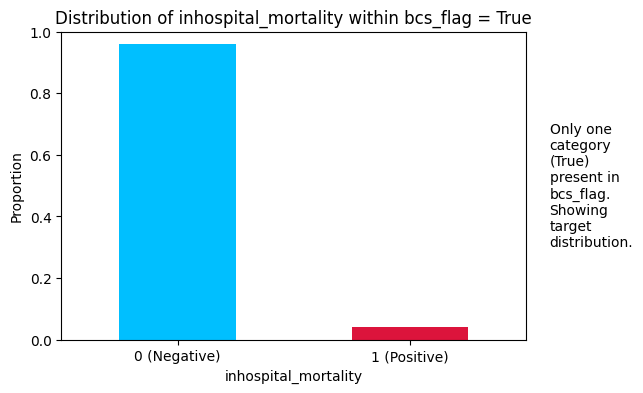

In [5]:
df = X.copy()
df.drop(columns=['height_cm_adm', 'weight_kg_adm'], inplace=True)
df.drop(columns=['bcseye_adm', 'bcsmotor_adm', 'bcsverbal_adm',
                 'bcseye_numeric', 'bcsmotor_numeric',
                 'bcsverbal_numeric'], inplace=True)
df.drop(columns=['spo2site1_pc_oxi_adm', 'spo2site2_pc_oxi_adm', 
                 'sqi1_perc_oxi_adm', 'sqi2_perc_oxi_adm'], inplace=True)

X = df.drop(columns=[target])
numerical_cols = X.select_dtypes(include='number').columns
categorical_cols = set(X.select_dtypes(exclude='number').columns.tolist() + X.select_dtypes(include='O').columns.tolist())
print(numerical_cols)
print(categorical_cols)
for col in categorical_cols:
    try:
        categorical_analysis(col, df, target, color=['#00BFFF', '#DC143C'])
    except Exception as e:
        print(col)
        print(e)

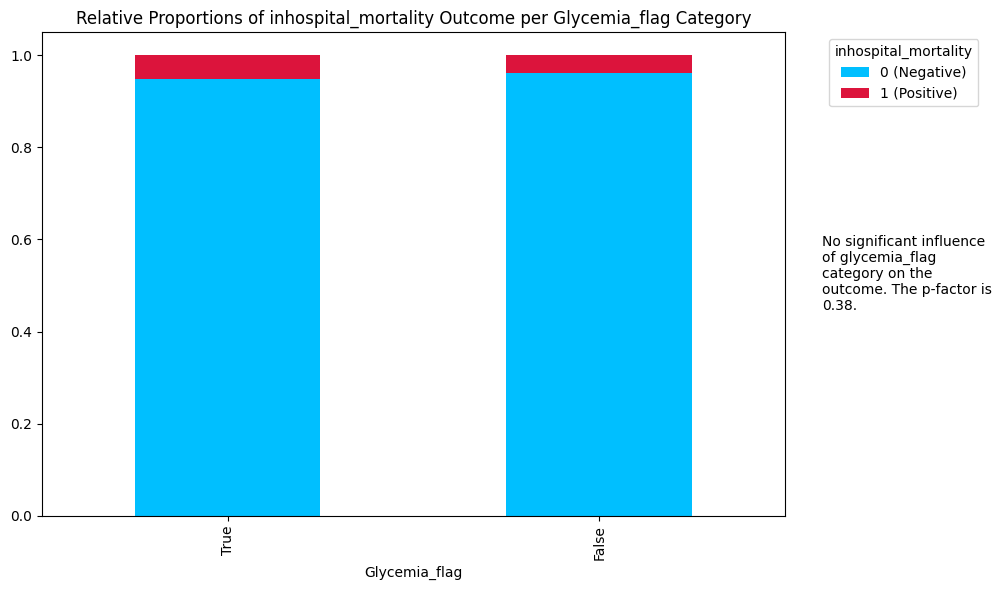

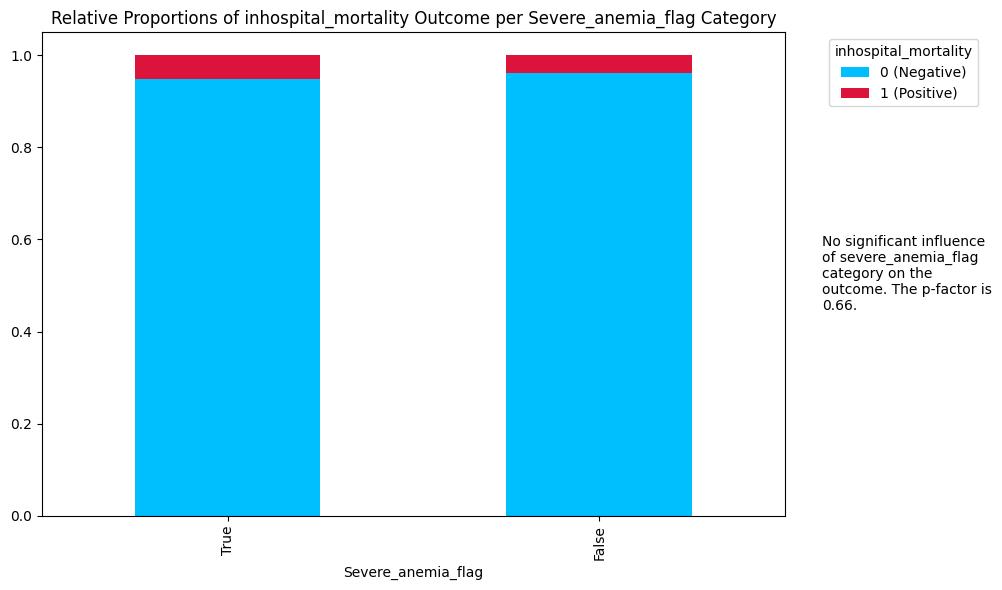

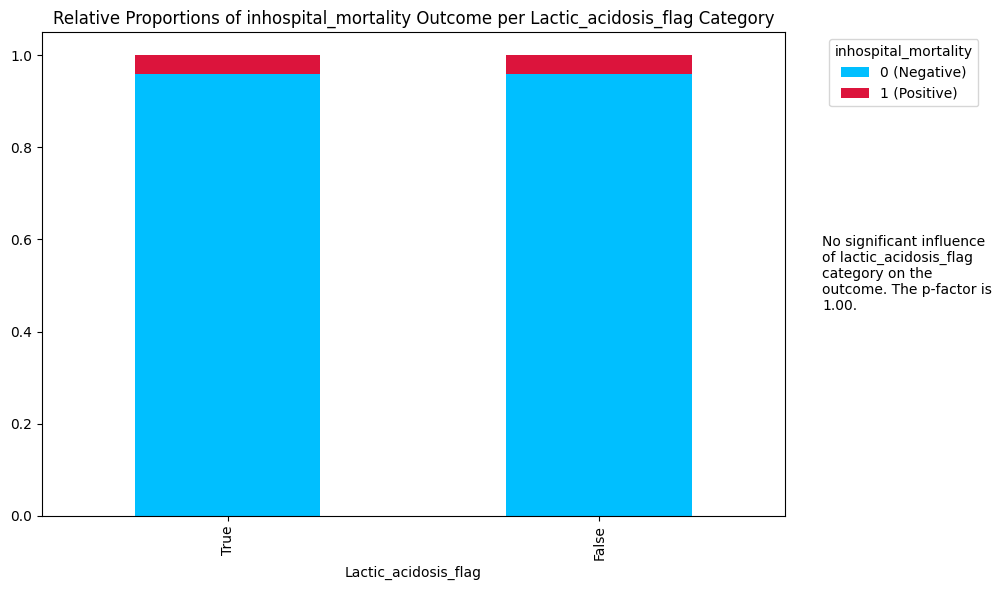

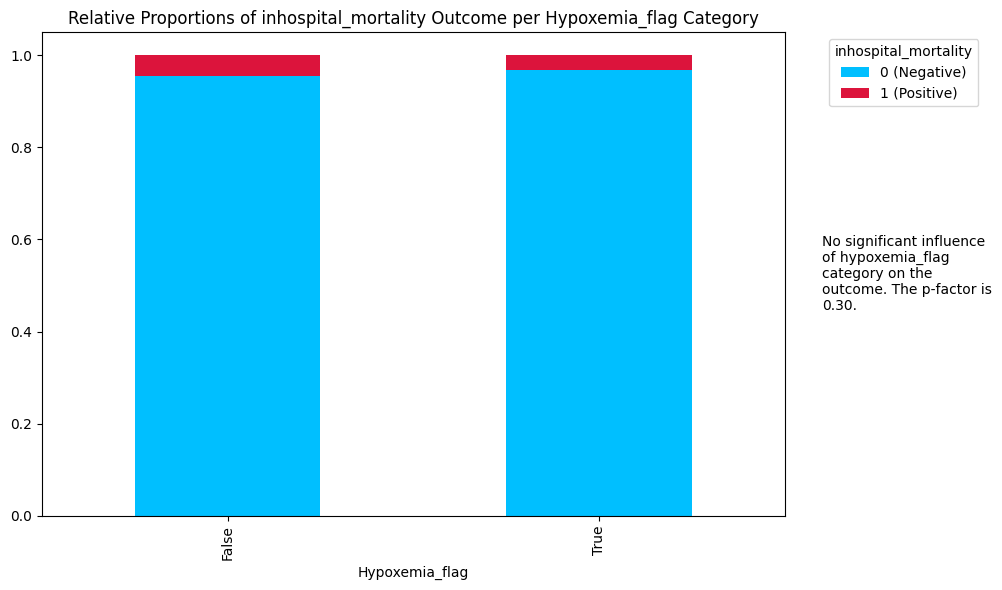

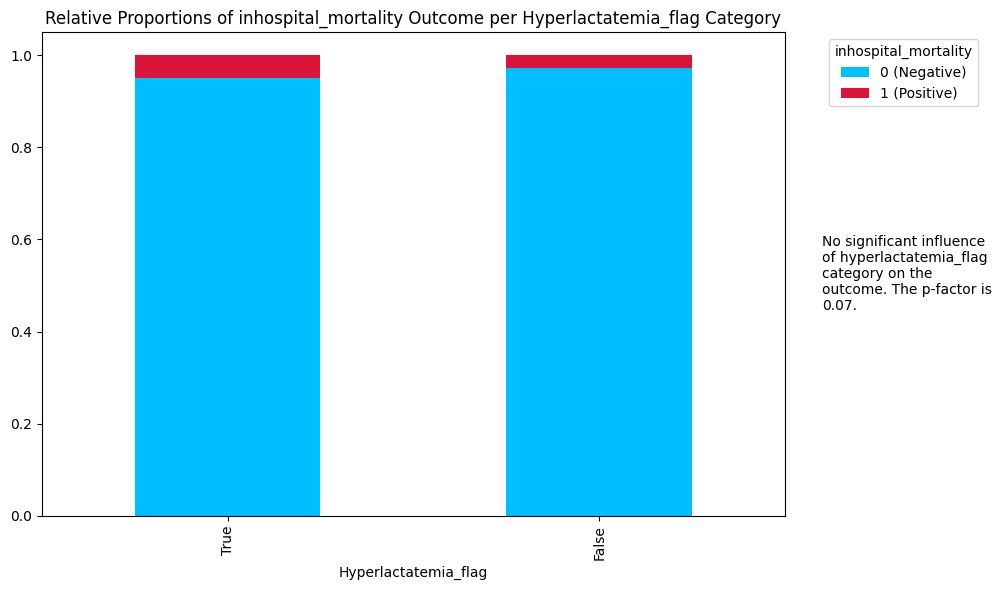

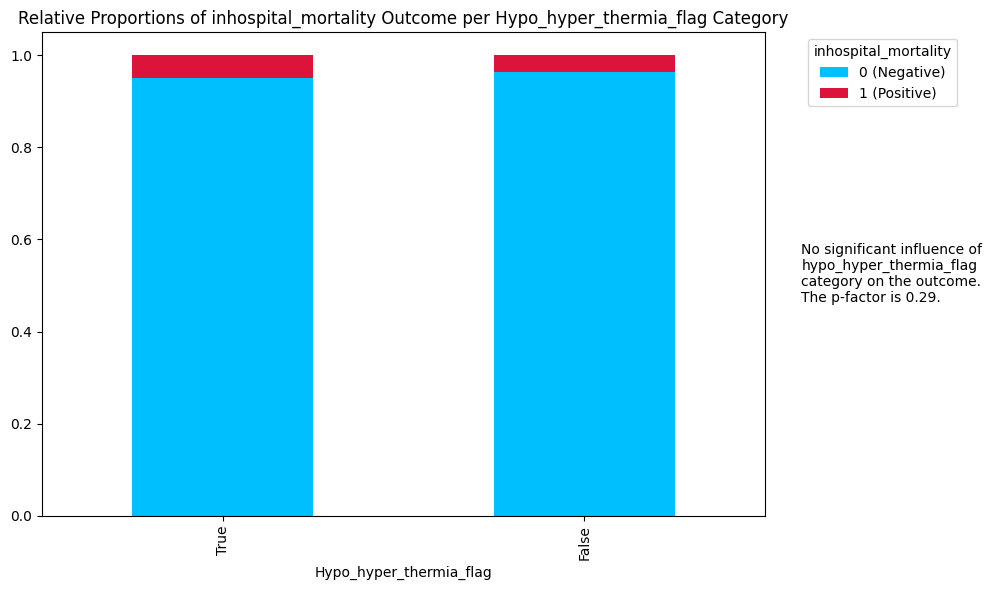

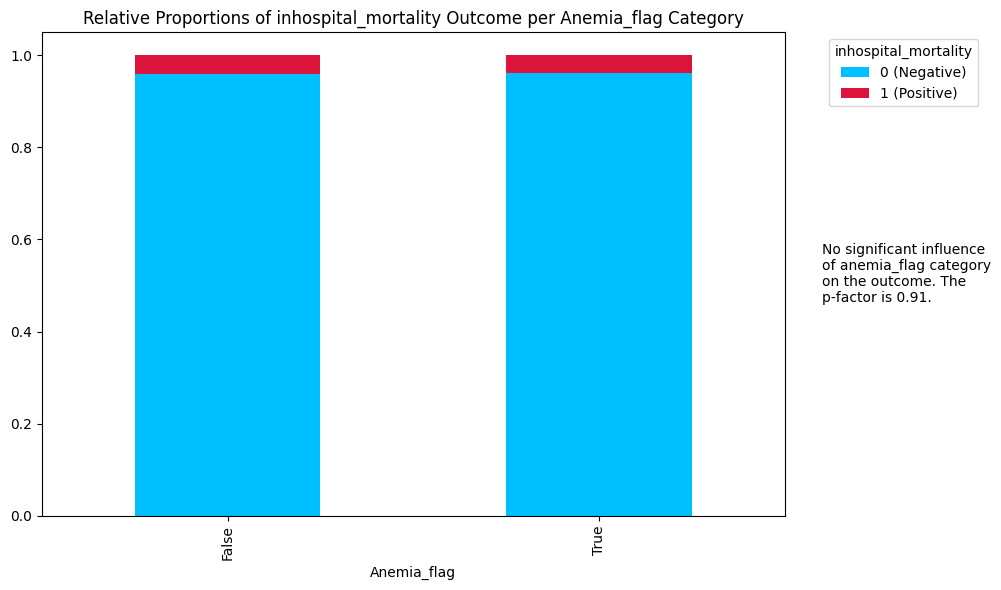

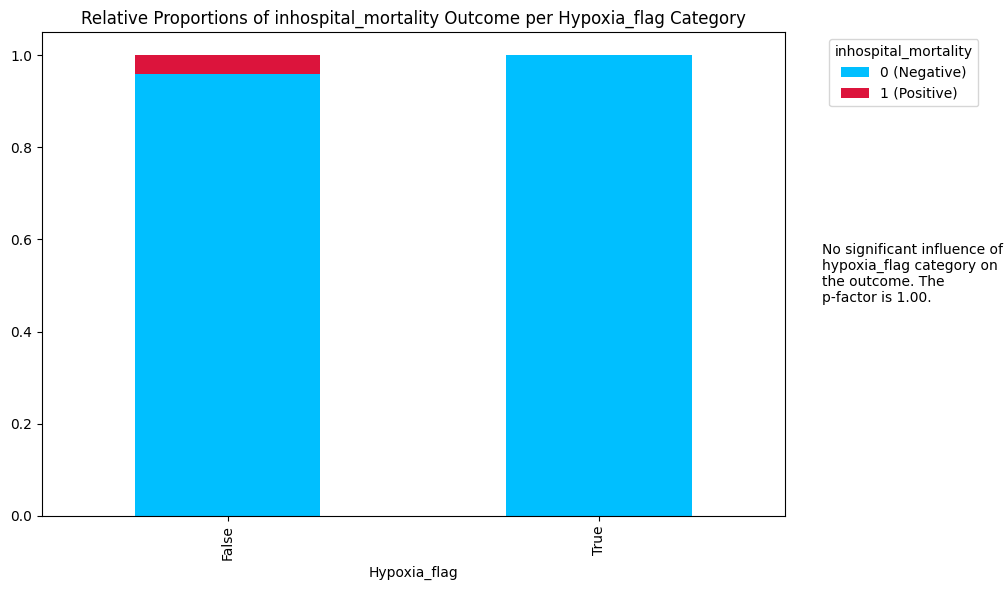

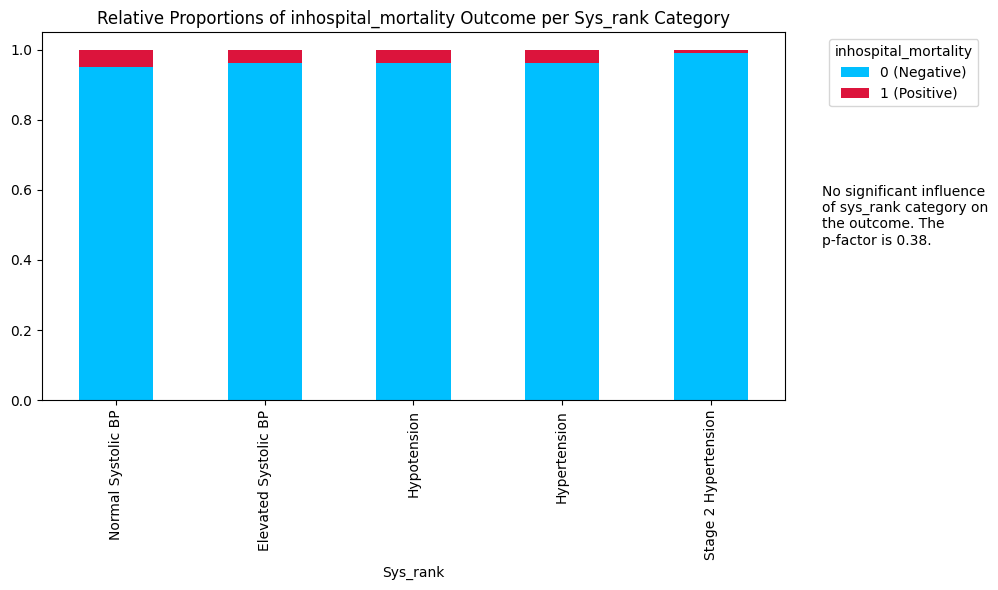

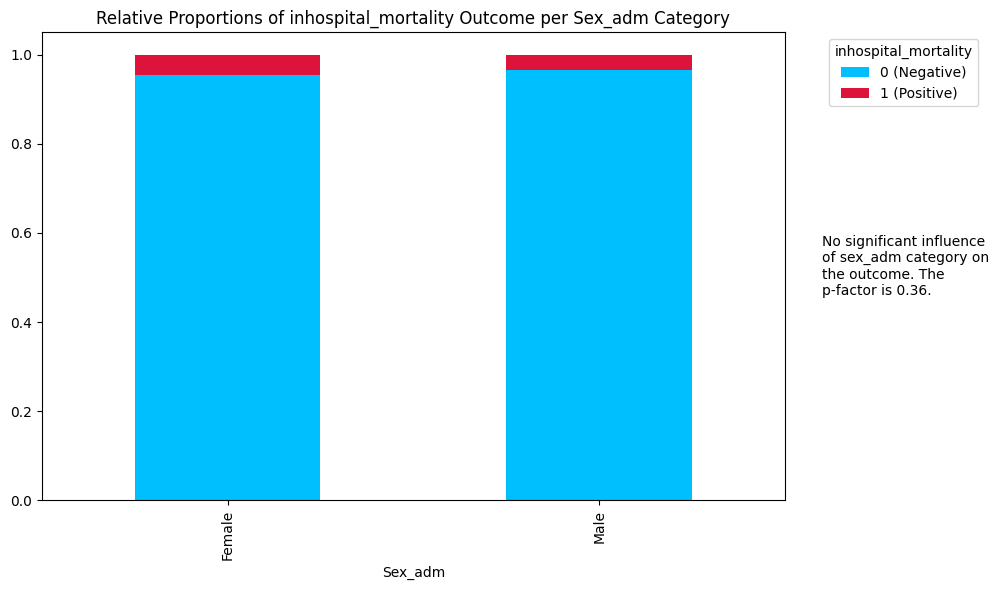

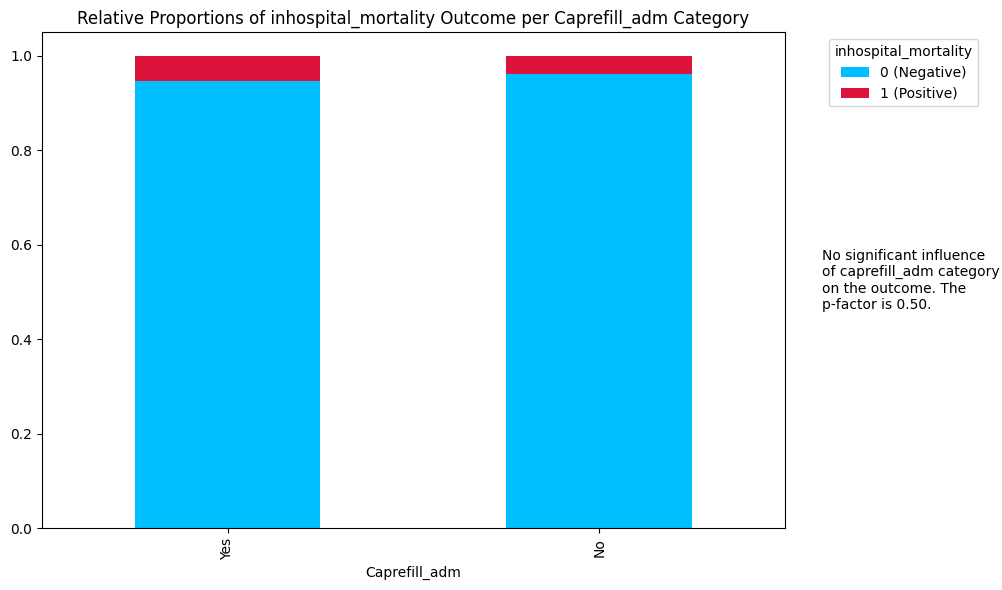

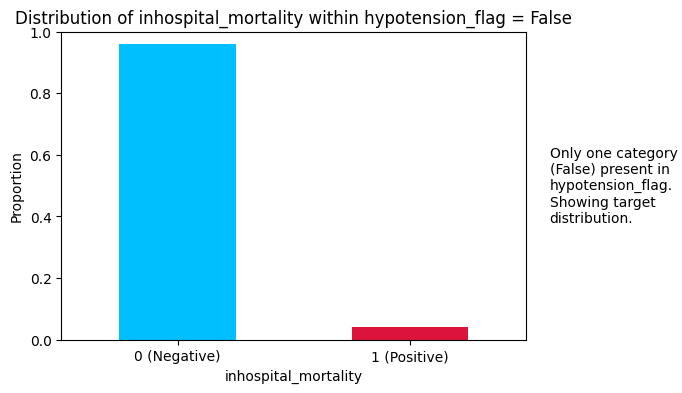

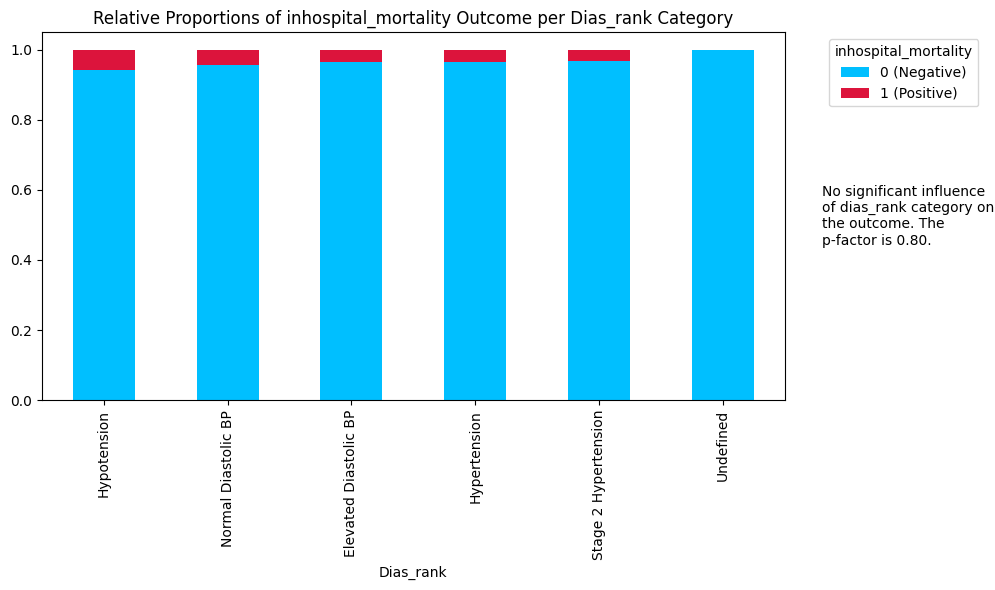

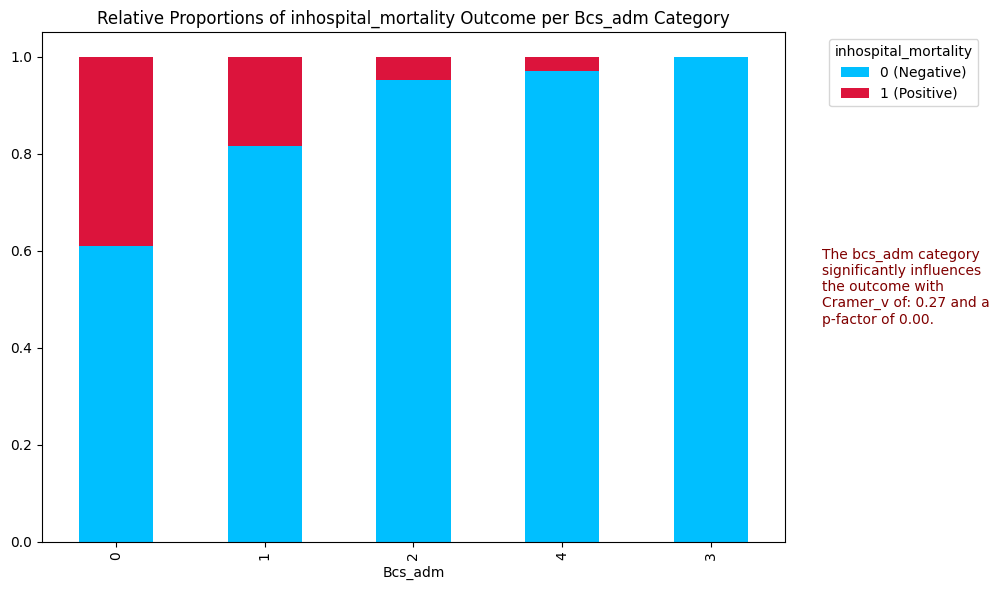

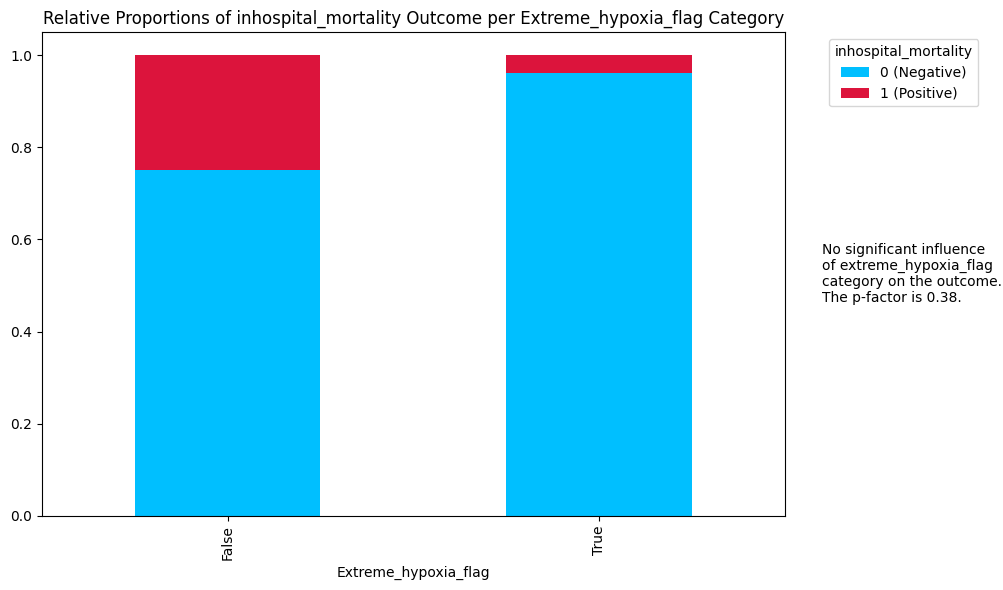

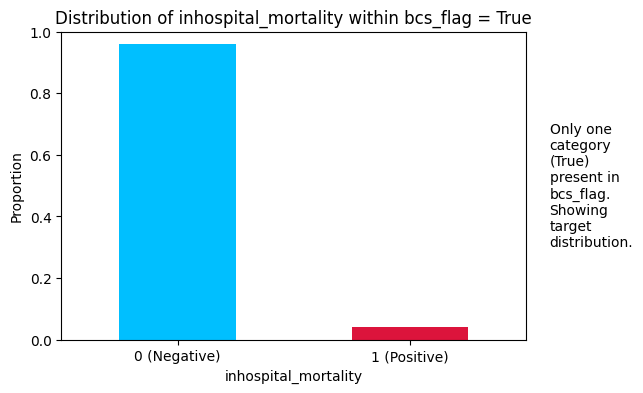

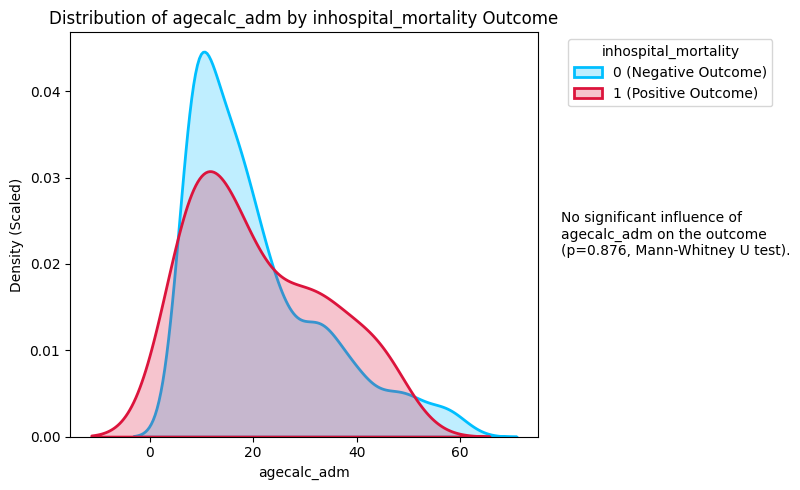

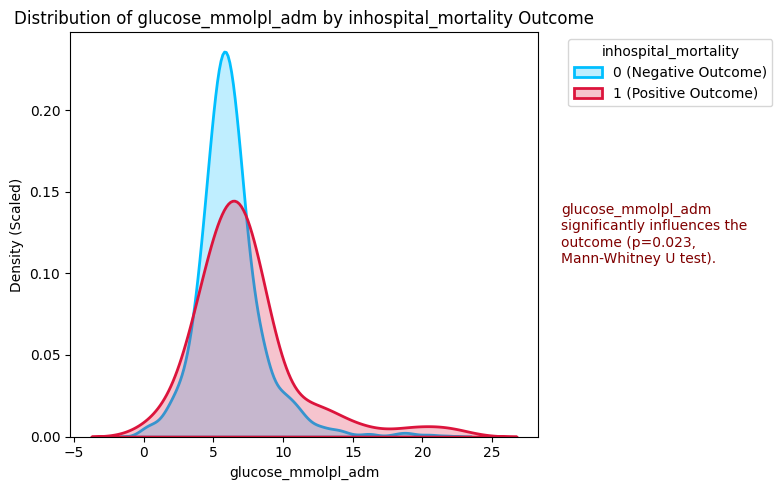

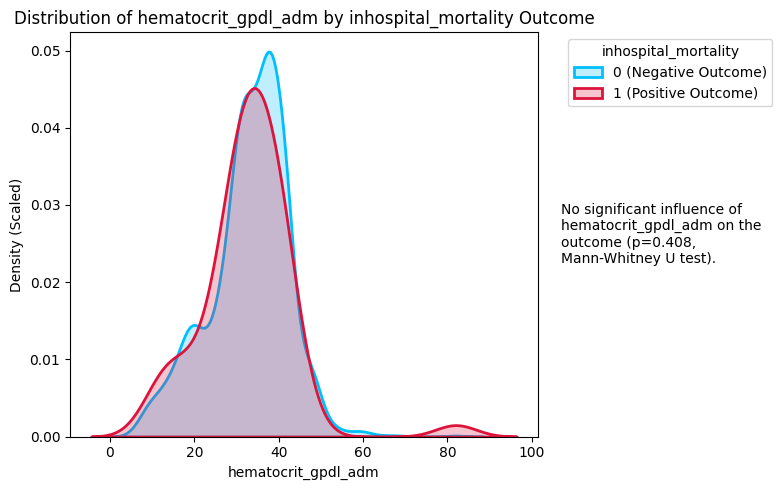

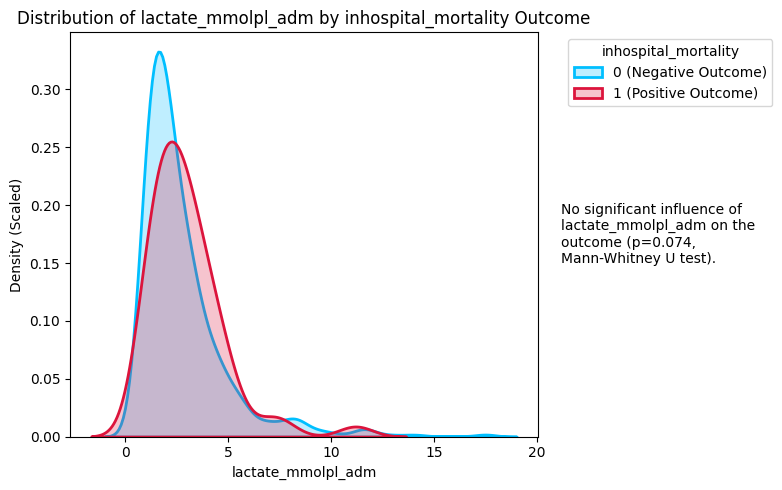

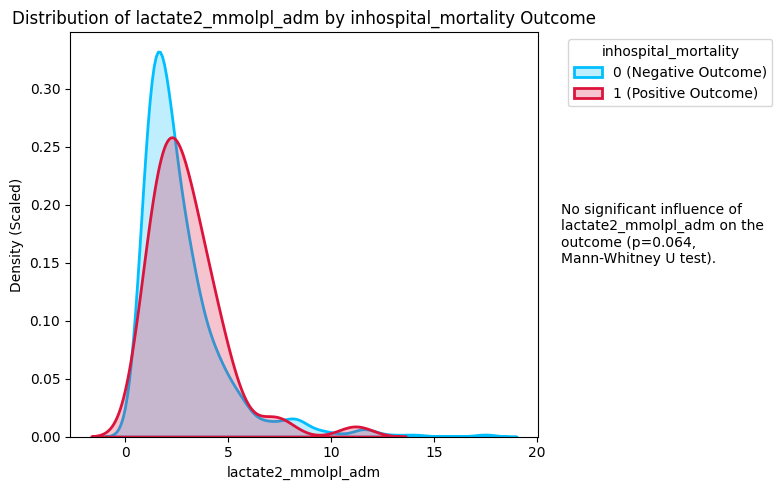

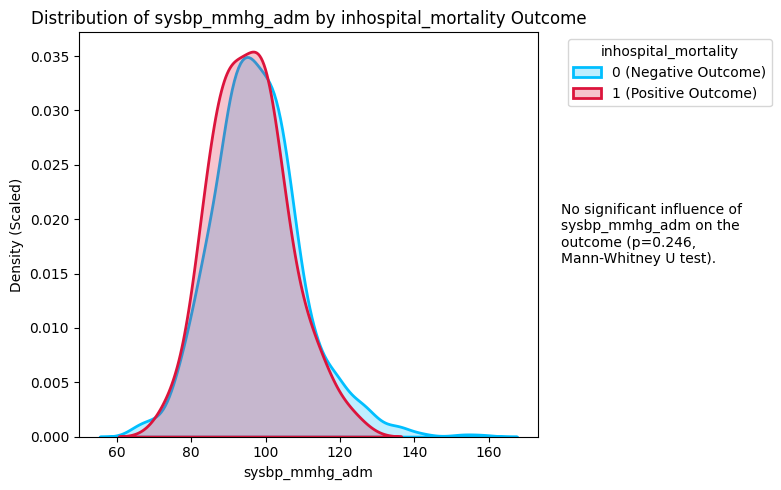

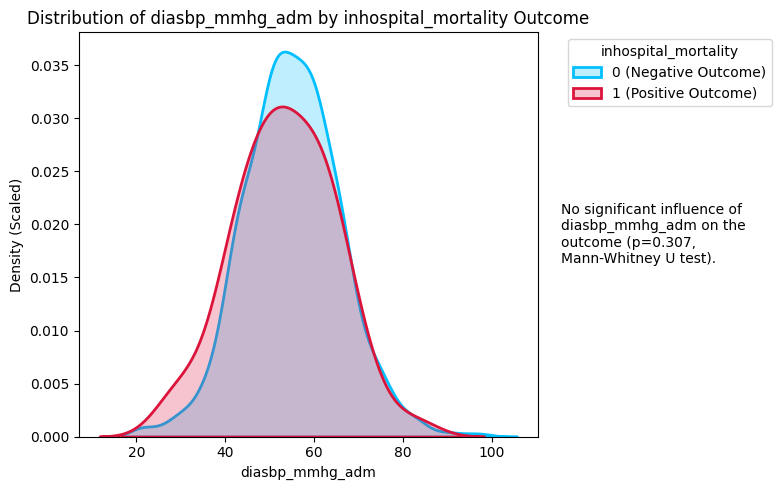

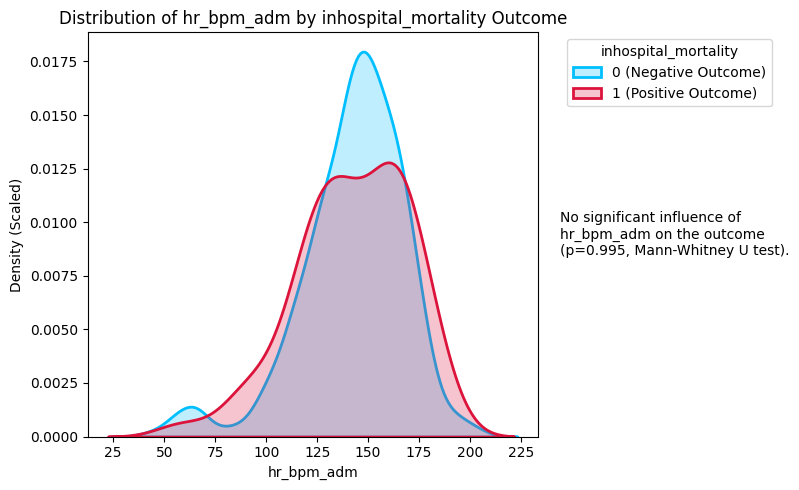

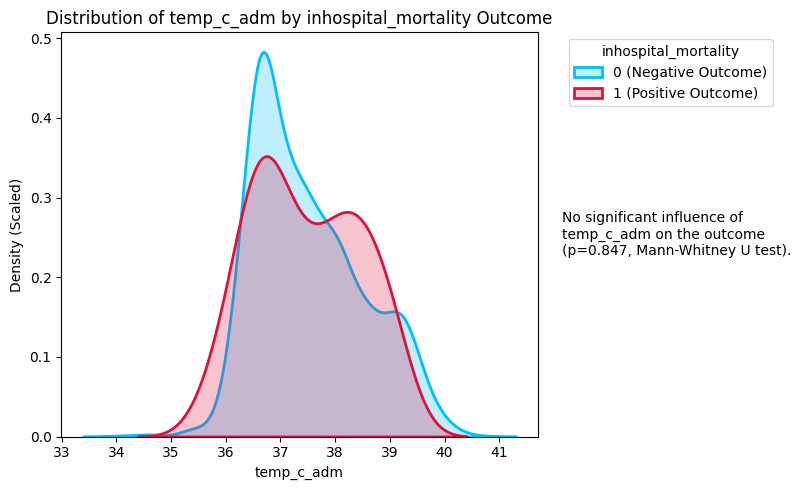

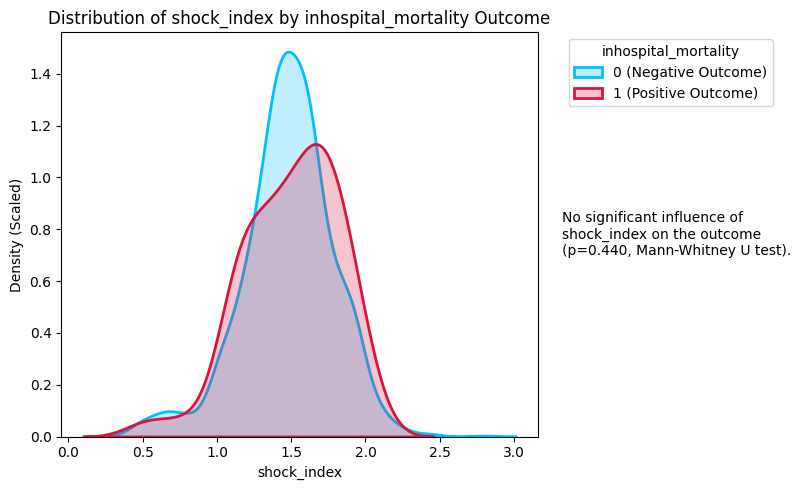

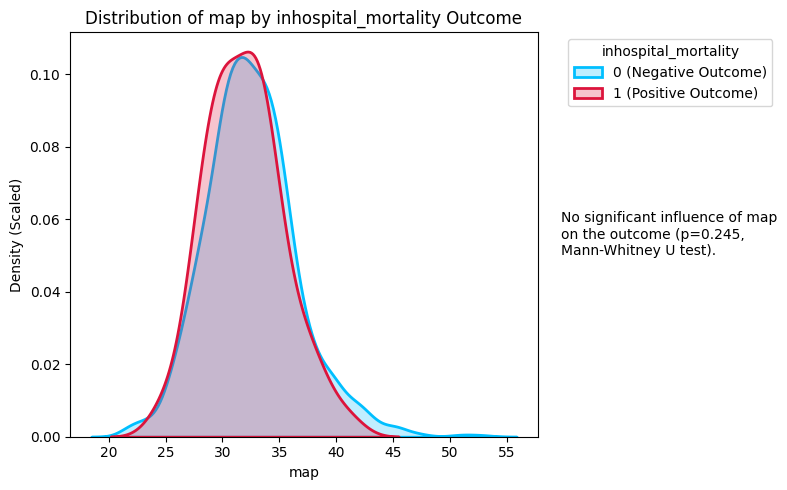

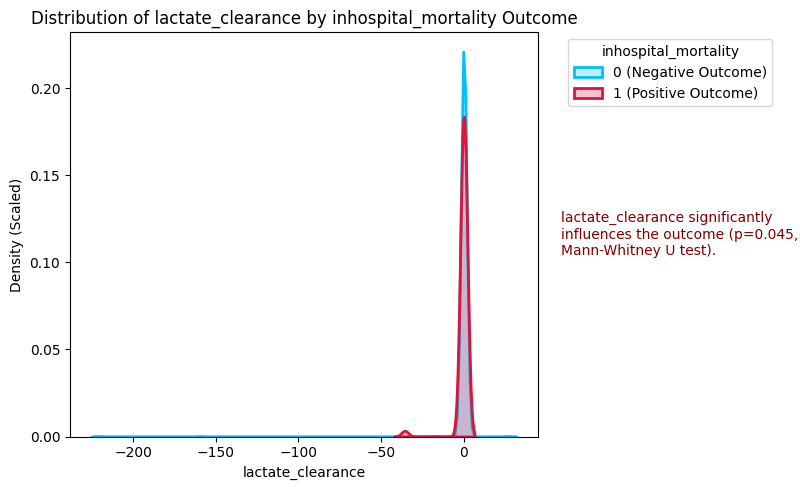

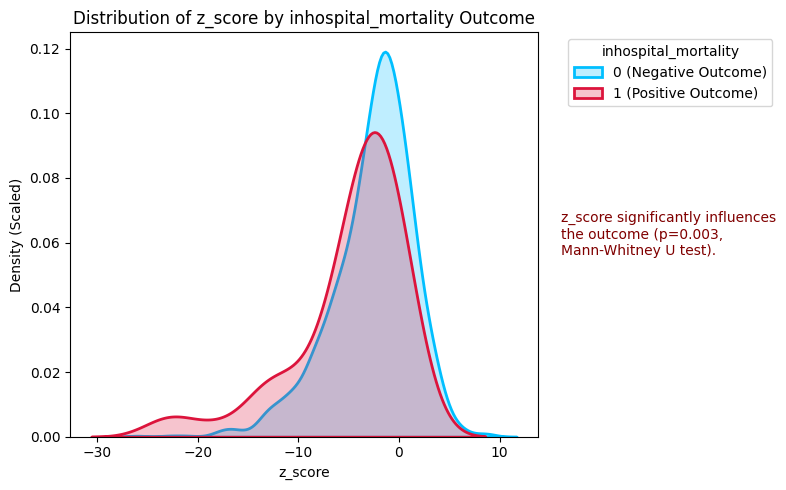

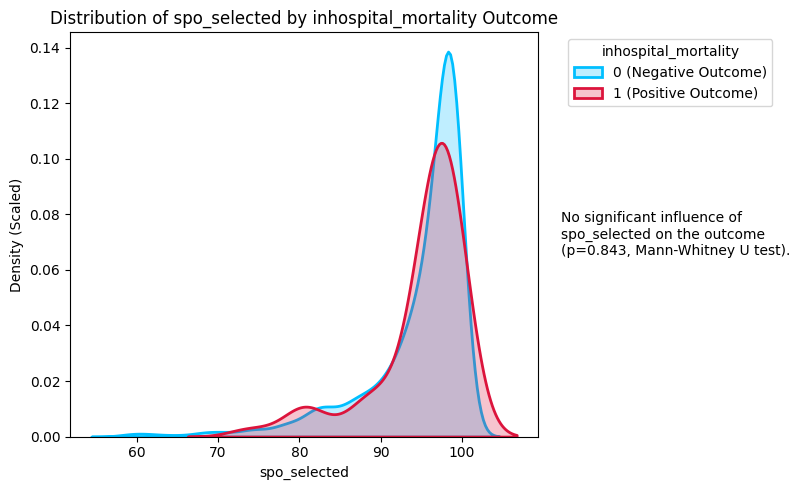

In [6]:
for col in categorical_cols:
    try:
        categorical_analysis(col, df, target, color=['#00BFFF', '#DC143C'])
    except Exception as e:
        print(col)
        print(e)
for col in numerical_cols:  
    numerical_analysis(col, df, target)

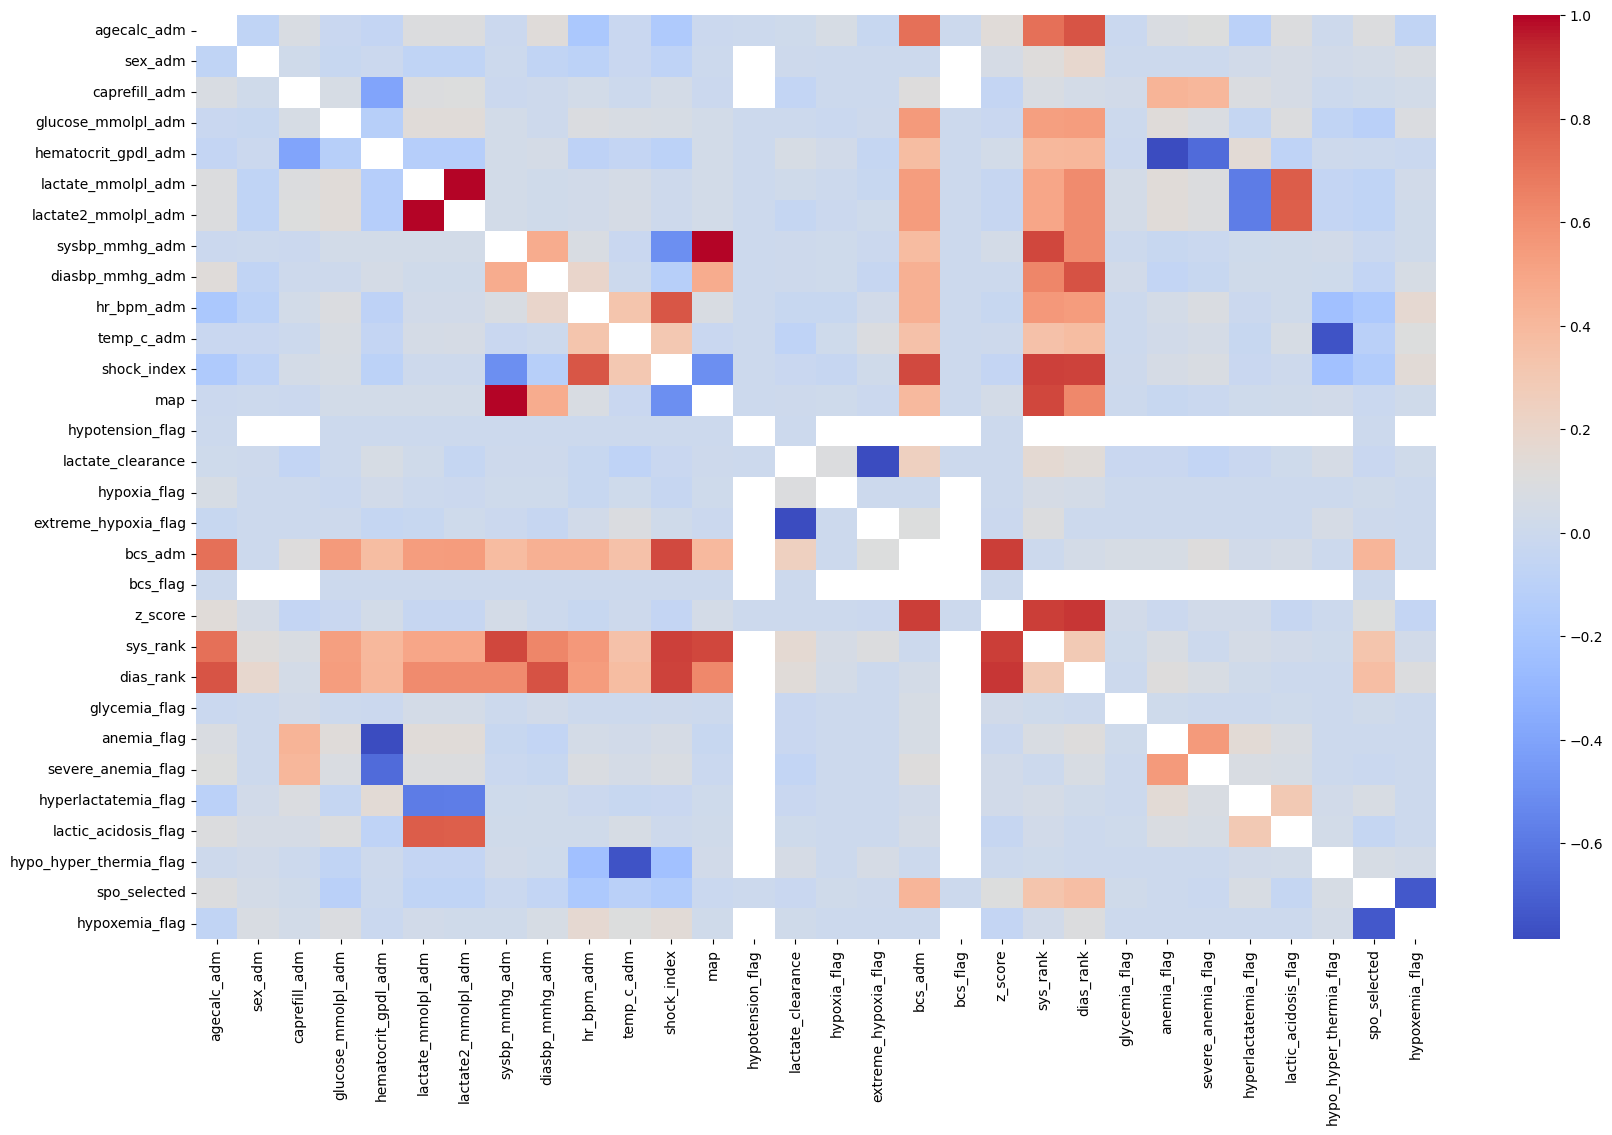

In [7]:
corr_matrix = heatmap_all_correlations(X)

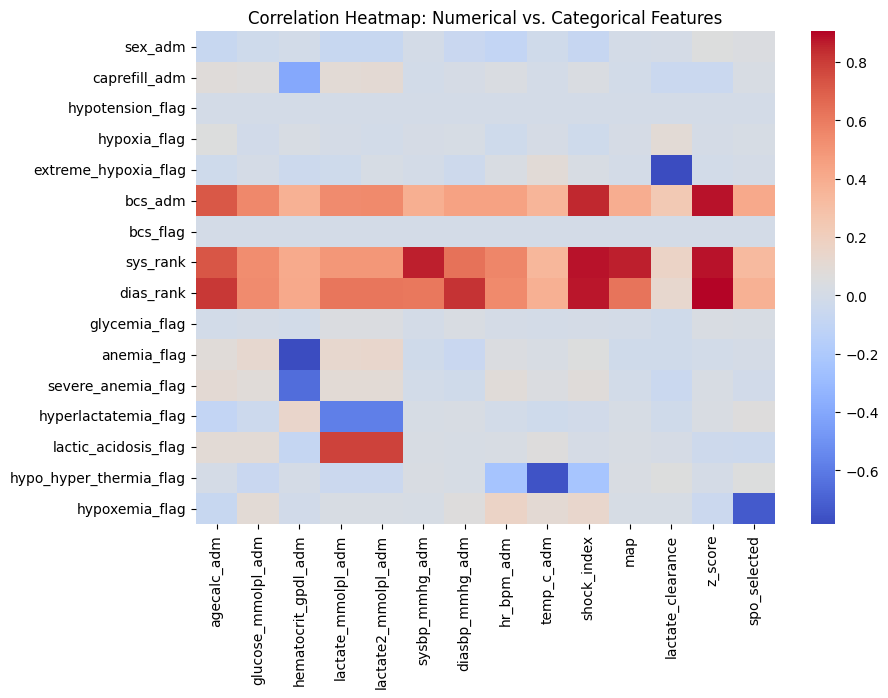

In [8]:
heatmap_categorical_numerical_cols(X)

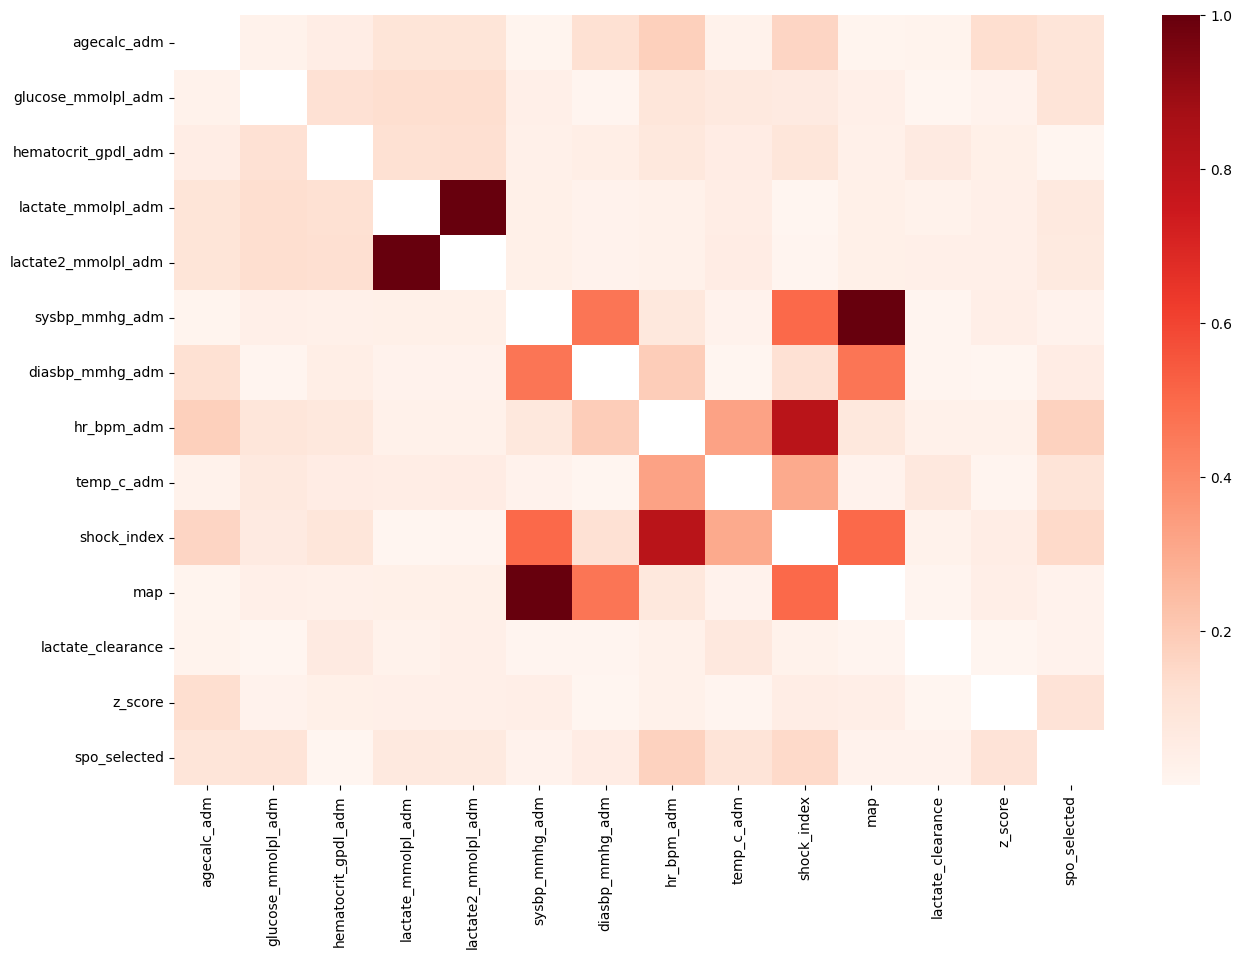

In [9]:
heatmap_numerical(X)

In [10]:
display(corr_matrix)

,agecalc_adm,sex_adm,caprefill_adm,glucose_mmolpl_adm,hematocrit_gpdl_adm,lactate_mmolpl_adm,lactate2_mmolpl_adm,sysbp_mmhg_adm,diasbp_mmhg_adm,hr_bpm_adm,...,sys_rank,dias_rank,glycemia_flag,anemia_flag,severe_anemia_flag,hyperlactatemia_flag,lactic_acidosis_flag,hypo_hyper_thermia_flag,spo_selected,hypoxemia_flag
agecalc_adm,NaN,-0.066878,0.073895,-0.020873,-0.048164,0.100524,0.099385,-0.008589,0.124977,-0.180030,...,0.720832,0.811878,-0.012272,0.082377,0.101726,-0.095757,0.095465,0.003762,0.095590,-0.065471
sex_adm,-0.066878,NaN,0.023089,-0.027566,-0.007602,-0.070347,-0.070409,-0.001560,-0.061110,-0.094287,...,0.118921,0.178685,0.000000,0.000000,0.000000,0.029972,0.058330,0.028047,0.040861,0.075364
caprefill_adm,0.073895,0.023089,NaN,0.061818,-0.400473,0.099460,0.102184,-0.006498,0.007893,0.036112,...,0.077514,0.041645,0.029936,0.426394,0.413415,0.089661,0.058359,0.000000,0.022387,0.036378
glucose_mmolpl_adm,-0.020873,-0.027566,0.061818,NaN,-0.120377,0.131553,0.131216,0.036043,0.007979,0.093248,...,0.532620,0.538537,0.003016,0.123073,0.080336,-0.042913,0.096910,-0.061032,-0.105164,0.093261
hematocrit_gpdl_adm,-0.048164,-0.007602,-0.400473,-0.120377,NaN,-0.123333,-0.126825,0.030963,0.046883,-0.081777,...,0.404855,0.413827,-0.006352,-0.784099,-0.658905,0.143050,-0.079968,0.006681,-0.000232,-0.017321
lactate_mmolpl_adm,0.100524,-0.070347,0.099460,0.131553,-0.123333,NaN,0.998115,0.033929,0.018333,0.025787,...,0.493226,0.614927,0.040835,0.132499,0.095485,-0.582705,0.784349,-0.047179,-0.071601,0.024622
lactate2_mmolpl_adm,0.099385,-0.070409,0.102184,0.131216,-0.126825,0.998115,NaN,0.033261,0.017711,0.027181,...,0.495369,0.615125,0.042812,0.133558,0.098366,-0.581536,0.783017,-0.050291,-0.070503,0.023415
sysbp_mmhg_adm,-0.008589,-0.001560,-0.006498,0.036043,0.030963,0.033929,0.033261,NaN,0.466737,0.078760,...,0.860061,0.613827,-0.001053,-0.025143,-0.011057,0.015750,0.023520,0.027282,-0.017774,0.019373
diasbp_mmhg_adm,0.124977,-0.061110,0.007893,0.007979,0.046883,0.018333,0.017711,0.466737,NaN,0.191314,...,0.634286,0.822112,0.027800,-0.059454,-0.025572,0.022211,0.017267,0.015430,-0.052835,0.064338
hr_bpm_adm,-0.180030,-0.094287,0.036112,0.093248,-0.081777,0.025787,0.027181,0.078760,0.191314,NaN,...,0.557092,0.544011,0.002486,0.040822,0.080931,-0.008174,0.023136,-0.239615,-0.173547,0.163643


In [11]:
df.to_csv("data_cleaned.csv", index=False)

In [12]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, KFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

def train_model(data, 
                target, 
                categorical_cols=categorical_cols, 
                numerical_cols=numerical_cols):
    # Separate features and target
    X = data.drop(columns=[target])
    y = data[target]
    categorical_cols = [col for col in categorical_cols if col in data.columns]
    numerical_cols = [col for col in numerical_cols if col in data.columns]

    # Define preprocessing for numerical and categorical columns
    numerical_transformer = StandardScaler()  # Scale numerical columns
    categorical_transformer = OneHotEncoder(drop='if_binary', sparse_output=False, handle_unknown='ignore')  # Encode categorical columns (binary)

    # Combine preprocessing steps
    preprocessor = ColumnTransformer(
        transformers=[
            ('num', numerical_transformer, numerical_cols),  # Apply to numerical columns
            ('cat', categorical_transformer, categorical_cols)  # Apply to categorical columns
        ]
    )

    kf = KFold(n_splits=5, shuffle=True, random_state=42)  # 5-fold CV

    # Initialize lists to store metrics from each fold
    precision_list = []
    recall_list = []
    f1_list = []
    support_list = []  # Store support from each fold
    class_1_precision_list = []
    class_1_recall_list = []
    class_1_f1_list = []

    # Store feature importances (averaged across folds)
    feature_importance_list = []

    for _, (train_idx, val_idx) in enumerate(kf.split(X)): 

        # Train-test split within this fold
        X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
        y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

        # Preprocess the data (scale numerical and encode categorical)
        X_train_preprocessed = preprocessor.fit_transform(X_train)
        X_val_preprocessed = preprocessor.transform(X_val)

        # Train the logistic regression model
        model = LogisticRegression(class_weight='balanced', solver='liblinear')
        model.fit(X_train_preprocessed, y_train)

        # Predictions
        y_pred = model.predict(X_val_preprocessed)

        # Get classification report metrics (you can extract precision, recall, f1-score, etc.)
        report = classification_report(y_val, y_pred, output_dict=True)

        # Store metrics for averaging
        precision_list.append(report['weighted avg']['precision'])
        recall_list.append(report['weighted avg']['recall'])
        f1_list.append(report['weighted avg']['f1-score'])
        support_list.append(report['weighted avg']['support'])

        # Store Class 1's specific metrics
        class_1_precision_list.append(report['1']['precision'])
        class_1_recall_list.append(report['1']['recall'])
        class_1_f1_list.append(report['1']['f1-score'])

        # Store feature importance
        feature_importance_list.append(model.coef_[0])

    # Calculate average metrics across all folds
    avg_precision = np.mean(precision_list)
    avg_recall = np.mean(recall_list)
    avg_f1 = np.mean(f1_list)

    avg_class_1_precision = np.mean(class_1_precision_list)
    avg_class_1_recall = np.mean(class_1_recall_list)
    avg_class_1_f1 = np.mean(class_1_f1_list)

    # Print average classification report
    print(f"Average Precision (weighted): {avg_precision:.4f}")
    print(f"Average Recall (weighted): {avg_recall:.4f}")
    print(f"Average F1-Score (weighted): {avg_f1:.4f}")

    print(f"\nAverage Class 1 Precision: {avg_class_1_precision:.4f}")
    print(f"Average Class 1 Recall: {avg_class_1_recall:.4f}")
    print(f"Average Class 1 F1-Score: {avg_class_1_f1:.4f}")

    # Compute average feature importance
    avg_feature_importance = np.mean(feature_importance_list, axis=0)

    # Get feature names after preprocessing
    numerical_feature_names = numerical_cols  # Numerical feature names remain the same
    categorical_feature_names = preprocessor.named_transformers_['cat'].get_feature_names_out(categorical_cols)
    feature_names = np.concatenate([numerical_feature_names, categorical_feature_names])

    # Convert to DataFrame
    feature_importance_df = pd.DataFrame({'Feature': feature_names, 'Coefficient': avg_feature_importance})
    feature_importance_df = feature_importance_df.sort_values(by='Coefficient', ascending=False)

    return feature_importance_df

In [13]:
train_model(df, target)

Average Precision (weighted): 0.9388
Average Recall (weighted): 0.7577
Average F1-Score (weighted): 0.8305

Average Class 1 Precision: 0.0845
Average Class 1 Recall: 0.5016
Average Class 1 F1-Score: 0.1423


,Feature,Coefficient
36,bcs_adm_0,2.765479
37,bcs_adm_1,1.397663
18,hyperlactatemia_flag_True,1.145429
25,sys_rank_Normal Systolic BP,0.929172
19,hypo_hyper_thermia_flag_True,0.688782
28,caprefill_adm_Yes,0.566362
22,sys_rank_Elevated Systolic BP,0.512026
1,glucose_mmolpl_adm,0.474190
32,dias_rank_Hypotension,0.432479
23,sys_rank_Hypertension,0.218060


In [14]:
# import pandas as pd
# from sklearn.preprocessing import PolynomialFeatures

# def encode_and_apply_polynomials(df, degree=2):
#     """
#     Encodes categorical (string or boolean) columns in a DataFrame to numerical (0/1) 
#     and applies PolynomialFeatures.

#     Args:
#         df: The input DataFrame.
#         degree: The degree of polynomial features.

#     Returns:
#         A DataFrame containing the polynomial features, or None if an error occurs.
#     """
#     df_encoded = df.copy()  # Create a copy to avoid modifying the original DataFrame

#     for col in df_encoded.columns:
#         if df_encoded[col].dtype == 'object' or df_encoded[col].dtype == 'bool':  # Check for string or boolean type
#             unique_values = df_encoded[col].unique()
#             num_unique = len(unique_values)

#             if num_unique == 2:  # Binary feature
#                 mapping = {unique_values[0]: 0, unique_values[1]: 1}  # Create a mapping
#                 df_encoded[col] = df_encoded[col].map(mapping)
#             elif num_unique > 2:  # Multi-class feature: One-hot encode
#                 df_encoded = pd.get_dummies(df_encoded, columns=[col], prefix=col, drop_first=False) # drop_first=True to drop the first category
#             elif num_unique == 1: # Only one unique value, drop the column
#                 df_encoded = df_encoded.drop(col, axis=1)
#             else:
#                 print(f"Column '{col}' has a data type that is not handled.")
#                 return None # or handle it differently
#         elif df_encoded[col].dtype == 'category': # Pandas categorical type
#             df_encoded = pd.get_dummies(df_encoded, columns=[col], prefix=col, drop_first=False) # drop_first=True to drop the first category

#     poly = PolynomialFeatures(degree=degree, include_bias=False)
#     poly_features = poly.fit_transform(df_encoded)
#     poly_df = pd.DataFrame(poly_features, columns=poly.get_feature_names_out())
#     return poly_df

# def visualize_X(X):
#     numerical_cols = X.select_dtypes(include='number').columns
#     categorical_cols = X.select_dtypes(exclude='number').columns
#     print(numerical_cols)
#     print(categorical_cols)
#     for col in categorical_cols:
#         try:
#             categorical_analysis(col, X, target, color=['#00BFFF', '#DC143C'])
#         except Exception as e:
#             print(col)
#             print(e)
#     for col in numerical_cols:  
#         numerical_analysis(col, X, target)


# X_combinations = df[categorical_cols].copy()

# poly_df = encode_and_apply_polynomials(X_combinations, degree=5)
# poly_df[target] = df[target]
# visualize_X(poly_df)

# if poly_df is not None:
#     print(poly_df)